### Advanced Topics: Covariate Shift, Regularization, and Learning Rate Schedular

In [1]:
import numpy as np
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim
from torch.optim.lr_scheduler import StepLR, ExponentialLR, ReduceLROnPlateau, CosineAnnealingLR, CyclicLR, LRScheduler

plt.style.use("dark_background")

np.random.seed(42)
torch.manual_seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


---

Let's simulate and detect covariate shift!


In [2]:
# Period 1 (Training)
np.random.seed(42)
n_sampels = 5000
n_features = 5

# Standard Gaussian (Normal) Distribution, mean = 0, std = 1
X_period1 = np.random.randn(n_sampels, n_features)
y_period1 = (X_period1[:, 0] + X_period1[:, 1] > 0).astype(int)

# Shifted Distribution, mean = 1.5, std = 1.2
X_period2 = np.random.randn(n_sampels, n_features) * 1.2 + 1.5
y_period2 = (X_period1[:, 0] + X_period1[:, 1] > 0).astype(int)

print("Simulated Two Time Periods:")
print(f"\nPeriod 1 (Training):")
print(f"  Feature 0 - Mean: {X_period1[:, 0].mean():.2f}, Std: {X_period1[:, 0].std():.2f}")
print(f"  Feature 1 - Mean: {X_period1[:, 1].mean():.2f}, Std: {X_period1[:, 1].std():.2f}")

print(f"\nPeriod 2 (Test):")
print(f"  Feature 0 - Mean: {X_period2[:, 0].mean():.2f}, Std: {X_period2[:, 0].std():.2f}")
print(f"  Feature 1 - Mean: {X_period2[:, 1].mean():.2f}, Std: {X_period2[:, 1].std():.2f}")

print(f"\n Notice the shift in distribution!")

Simulated Two Time Periods:

Period 1 (Training):
  Feature 0 - Mean: 0.01, Std: 1.02
  Feature 1 - Mean: 0.02, Std: 0.99

Period 2 (Test):
  Feature 0 - Mean: 1.49, Std: 1.21
  Feature 1 - Mean: 1.51, Std: 1.20

 Notice the shift in distribution!


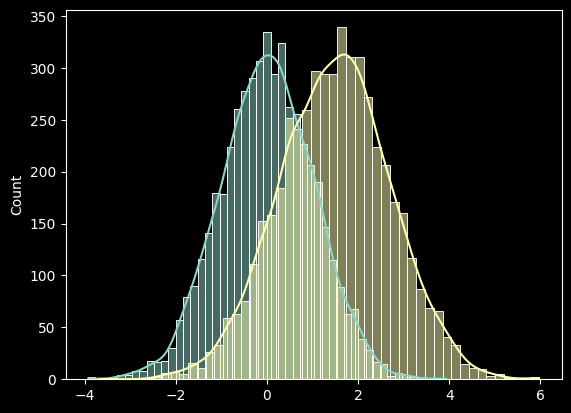

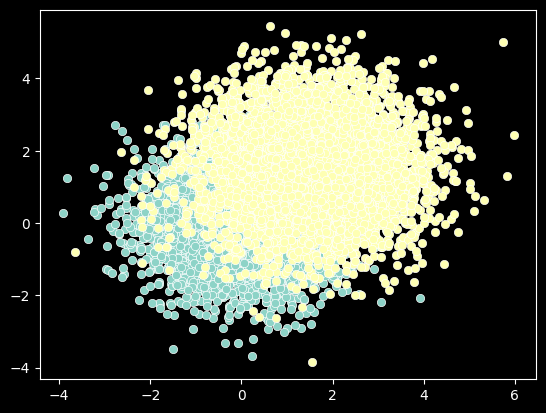

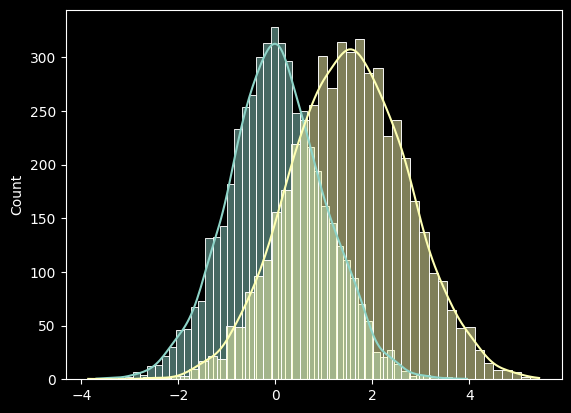

In [3]:
sns.histplot(X_period1[:, 0], kde=True)
sns.histplot(X_period2[:, 0], kde=True)
plt.show()

sns.scatterplot(x=X_period1[:, 0], y=X_period1[:, 1])
sns.scatterplot(x=X_period2[:, 0], y=X_period2[:, 1])
plt.show()

sns.histplot(X_period1[:, 1], kde=True)
sns.histplot(X_period2[:, 1], kde=True)
plt.show()

#### The **Overlapping Coefficient (OVL)** to evaluate the common area betweeb two distributions

$$OVL = \int_{-\infty}^{\infty} \min(P(x), Q(x)) dx$$

In [4]:
import numpy as np
from scipy.stats import gaussian_kde
from scipy.integrate import trapezoid

def calculate_overlapping_coefficient(X_period1, X_period2, num_points=1000):
    """
    Calculates the Overlapping Coefficient (OVL) between two data samples.
    """

    kde_p = gaussian_kde(X_period1)
    kde_q = gaussian_kde(X_period2)

    min_x = min(np.min(X_period1), np.min(X_period2))
    max_x = max(np.max(X_period1), np.max(X_period2))
    buffer = (max_x - min_x) * 0.1
    x_grid = np.linspace(min_x - buffer, max_x + buffer, num_points)

    P_x = kde_p.evaluate(x_grid)
    Q_x = kde_q.evaluate(x_grid)

    min_density = np.minimum(P_x, Q_x)

    ovl = trapezoid(min_density, x_grid)

    return ovl

overlap_ratio_0 = calculate_overlapping_coefficient(X_period1[:, 0], X_period2[:, 0])
print(f"Overlapping Coefficient (OVL) Feature 0: {overlap_ratio_0:.4f}")

overlap_ratio_1 = calculate_overlapping_coefficient(X_period1[:, 1], X_period2[:, 1])
print(f"Overlapping Coefficient (OVL) Feature 1: {overlap_ratio_1:.4f}")

Overlapping Coefficient (OVL) Feature 0: 0.5134
Overlapping Coefficient (OVL) Feature 1: 0.4997


C:\Users\mwafy\AppData\Local\Temp\ipykernel_22888\3664691974.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1, 1].boxplot(feature_data, positions=positions, widths=0.6, patch_artist=True,


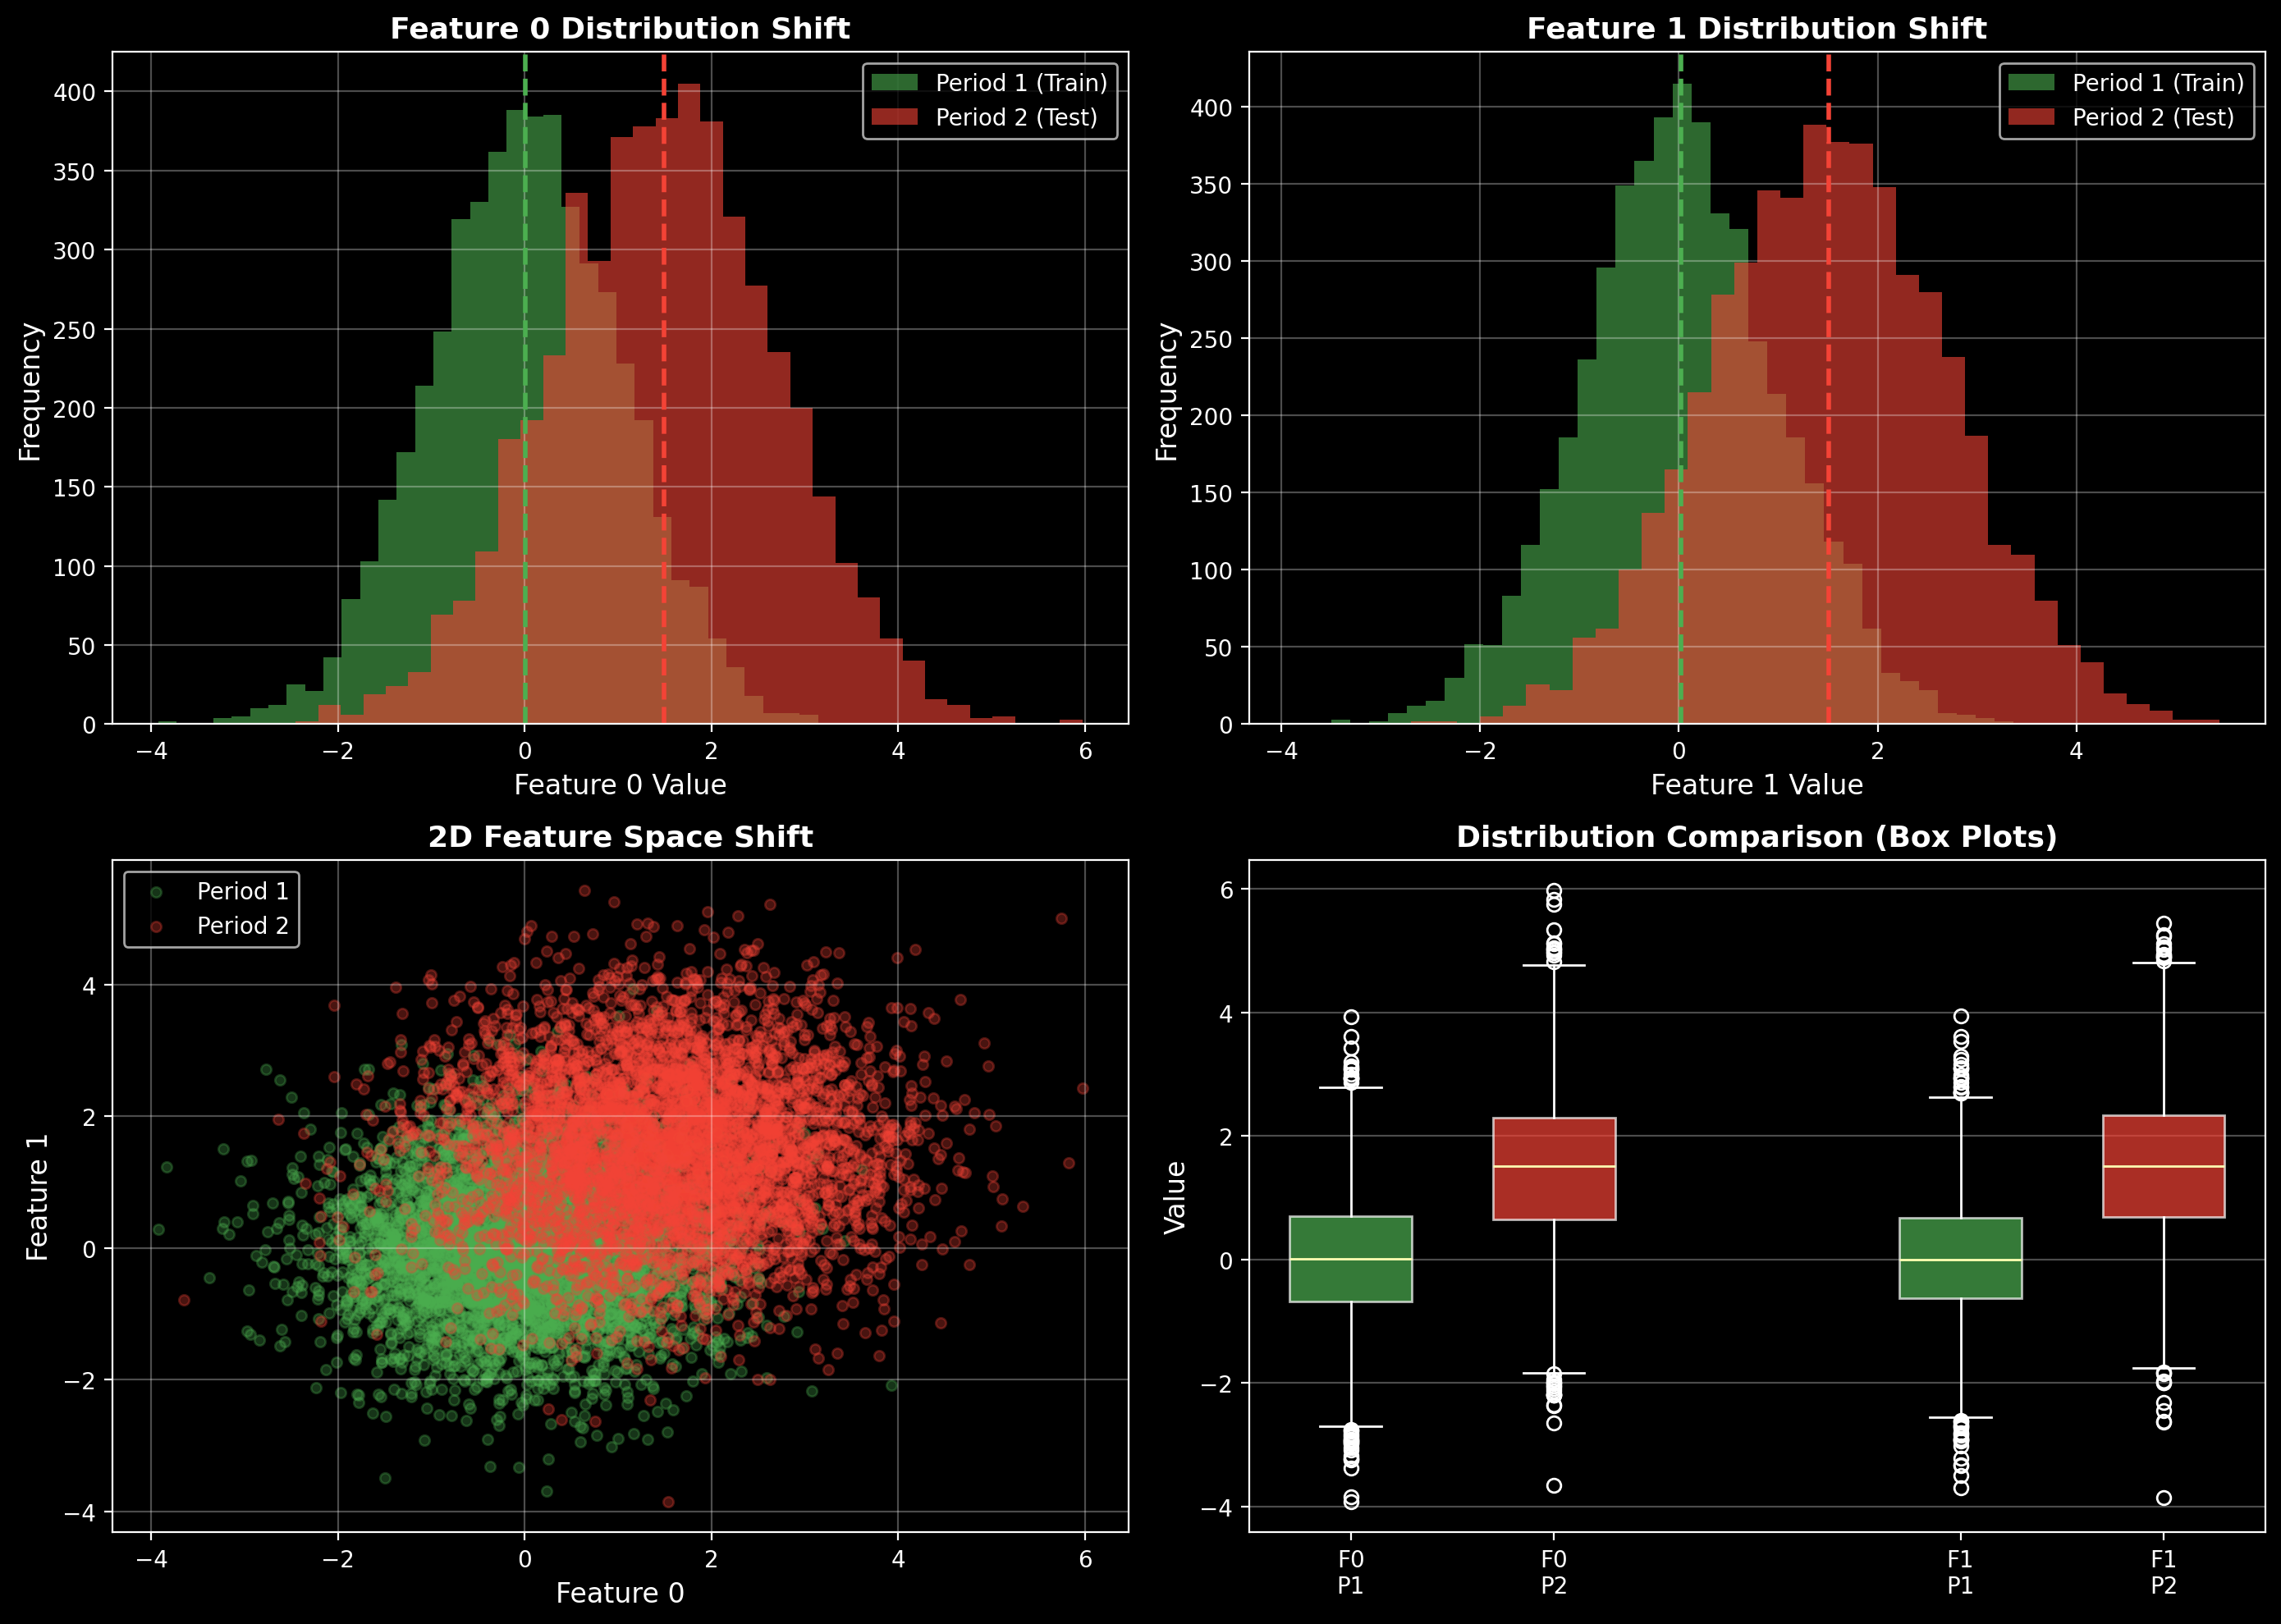

 Clear evidence of covariate shift in both features!


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=200)

# Plot Feature 0 distribution
axes[0, 0].hist(X_period1[:, 0], bins=40, alpha=0.6, label='Period 1 (Train)', color='#4CAF50')
axes[0, 0].hist(X_period2[:, 0], bins=40, alpha=0.6, label='Period 2 (Test)', color='#f44336')
axes[0, 0].axvline(X_period1[:, 0].mean(), color='#4CAF50', linestyle='--', linewidth=2)
axes[0, 0].axvline(X_period2[:, 0].mean(), color='#f44336', linestyle='--', linewidth=2)
axes[0, 0].set_xlabel('Feature 0 Value', fontsize=12)
axes[0, 0].set_ylabel('Frequency', fontsize=12)
axes[0, 0].set_title('Feature 0 Distribution Shift', fontsize=13, fontweight='bold')
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(True, alpha=0.3)

# Plot Feature 1 distribution
axes[0, 1].hist(X_period1[:, 1], bins=40, alpha=0.6, label='Period 1 (Train)', color='#4CAF50')
axes[0, 1].hist(X_period2[:, 1], bins=40, alpha=0.6, label='Period 2 (Test)', color='#f44336')
axes[0, 1].axvline(X_period1[:, 1].mean(), color='#4CAF50', linestyle='--', linewidth=2)
axes[0, 1].axvline(X_period2[:, 1].mean(), color='#f44336', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('Feature 1 Value', fontsize=12)
axes[0, 1].set_ylabel('Frequency', fontsize=12)
axes[0, 1].set_title('Feature 1 Distribution Shift', fontsize=13, fontweight='bold')
axes[0, 1].legend(fontsize=10)
axes[0, 1].grid(True, alpha=0.3)

# Scatter plot: Feature 0 vs Feature 1
axes[1, 0].scatter(X_period1[:, 0], X_period1[:, 1], alpha=0.3, label='Period 1', color='#4CAF50', s=20)
axes[1, 0].scatter(X_period2[:, 0], X_period2[:, 1], alpha=0.3, label='Period 2', color='#f44336', s=20)
axes[1, 0].set_xlabel('Feature 0', fontsize=12)
axes[1, 0].set_ylabel('Feature 1', fontsize=12)
axes[1, 0].set_title('2D Feature Space Shift', fontsize=13, fontweight='bold')
axes[1, 0].legend(fontsize=10)
axes[1, 0].grid(True, alpha=0.3)

# Box plots comparison
feature_data = [
    X_period1[:, 0], X_period2[:, 0],
    X_period1[:, 1], X_period2[:, 1]
]
positions = [1, 2, 4, 5]
bp = axes[1, 1].boxplot(feature_data, positions=positions, widths=0.6, patch_artist=True,
                        labels=['F0\nP1', 'F0\nP2', 'F1\nP1', 'F1\nP2'])
colors = ['#4CAF50', '#f44336', '#4CAF50', '#f44336']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1, 1].set_ylabel('Value', fontsize=12)
axes[1, 1].set_title('Distribution Comparison (Box Plots)', fontsize=13, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print(" Clear evidence of covariate shift in both features!")

### Statistical Test: Kolmogorov-Smirnov Test (Non-Parametric Test)

In [6]:
for i in range(n_features):
    statistic, p_value = ks_2samp(X_period1[:, i], X_period2[:, i])
    print(f"Features: {i}")
    print(f"  KS Statistic: {statistic:.4f}")
    print(f"  p-value: {p_value:.6f}")
    
    if p_value < 0.01:
        print("SIGNIFICANT SHIFT DETECTED (p < 0.01)")
    else:
        print("No significant shift")
    print()

print("Interpretation:")
print("  - Low p-value (< 0.01) → distributions are different")
print("  - High KS statistic → large difference between distributions")


Features: 0
  KS Statistic: 0.4958
  p-value: 0.000000
SIGNIFICANT SHIFT DETECTED (p < 0.01)

Features: 1
  KS Statistic: 0.5096
  p-value: 0.000000
SIGNIFICANT SHIFT DETECTED (p < 0.01)

Features: 2
  KS Statistic: 0.5100
  p-value: 0.000000
SIGNIFICANT SHIFT DETECTED (p < 0.01)

Features: 3
  KS Statistic: 0.5252
  p-value: 0.000000
SIGNIFICANT SHIFT DETECTED (p < 0.01)

Features: 4
  KS Statistic: 0.5094
  p-value: 0.000000
SIGNIFICANT SHIFT DETECTED (p < 0.01)

Interpretation:
  - Low p-value (< 0.01) → distributions are different
  - High KS statistic → large difference between distributions


##### the largest vertical gap between these two curves is exactly the KS statistic

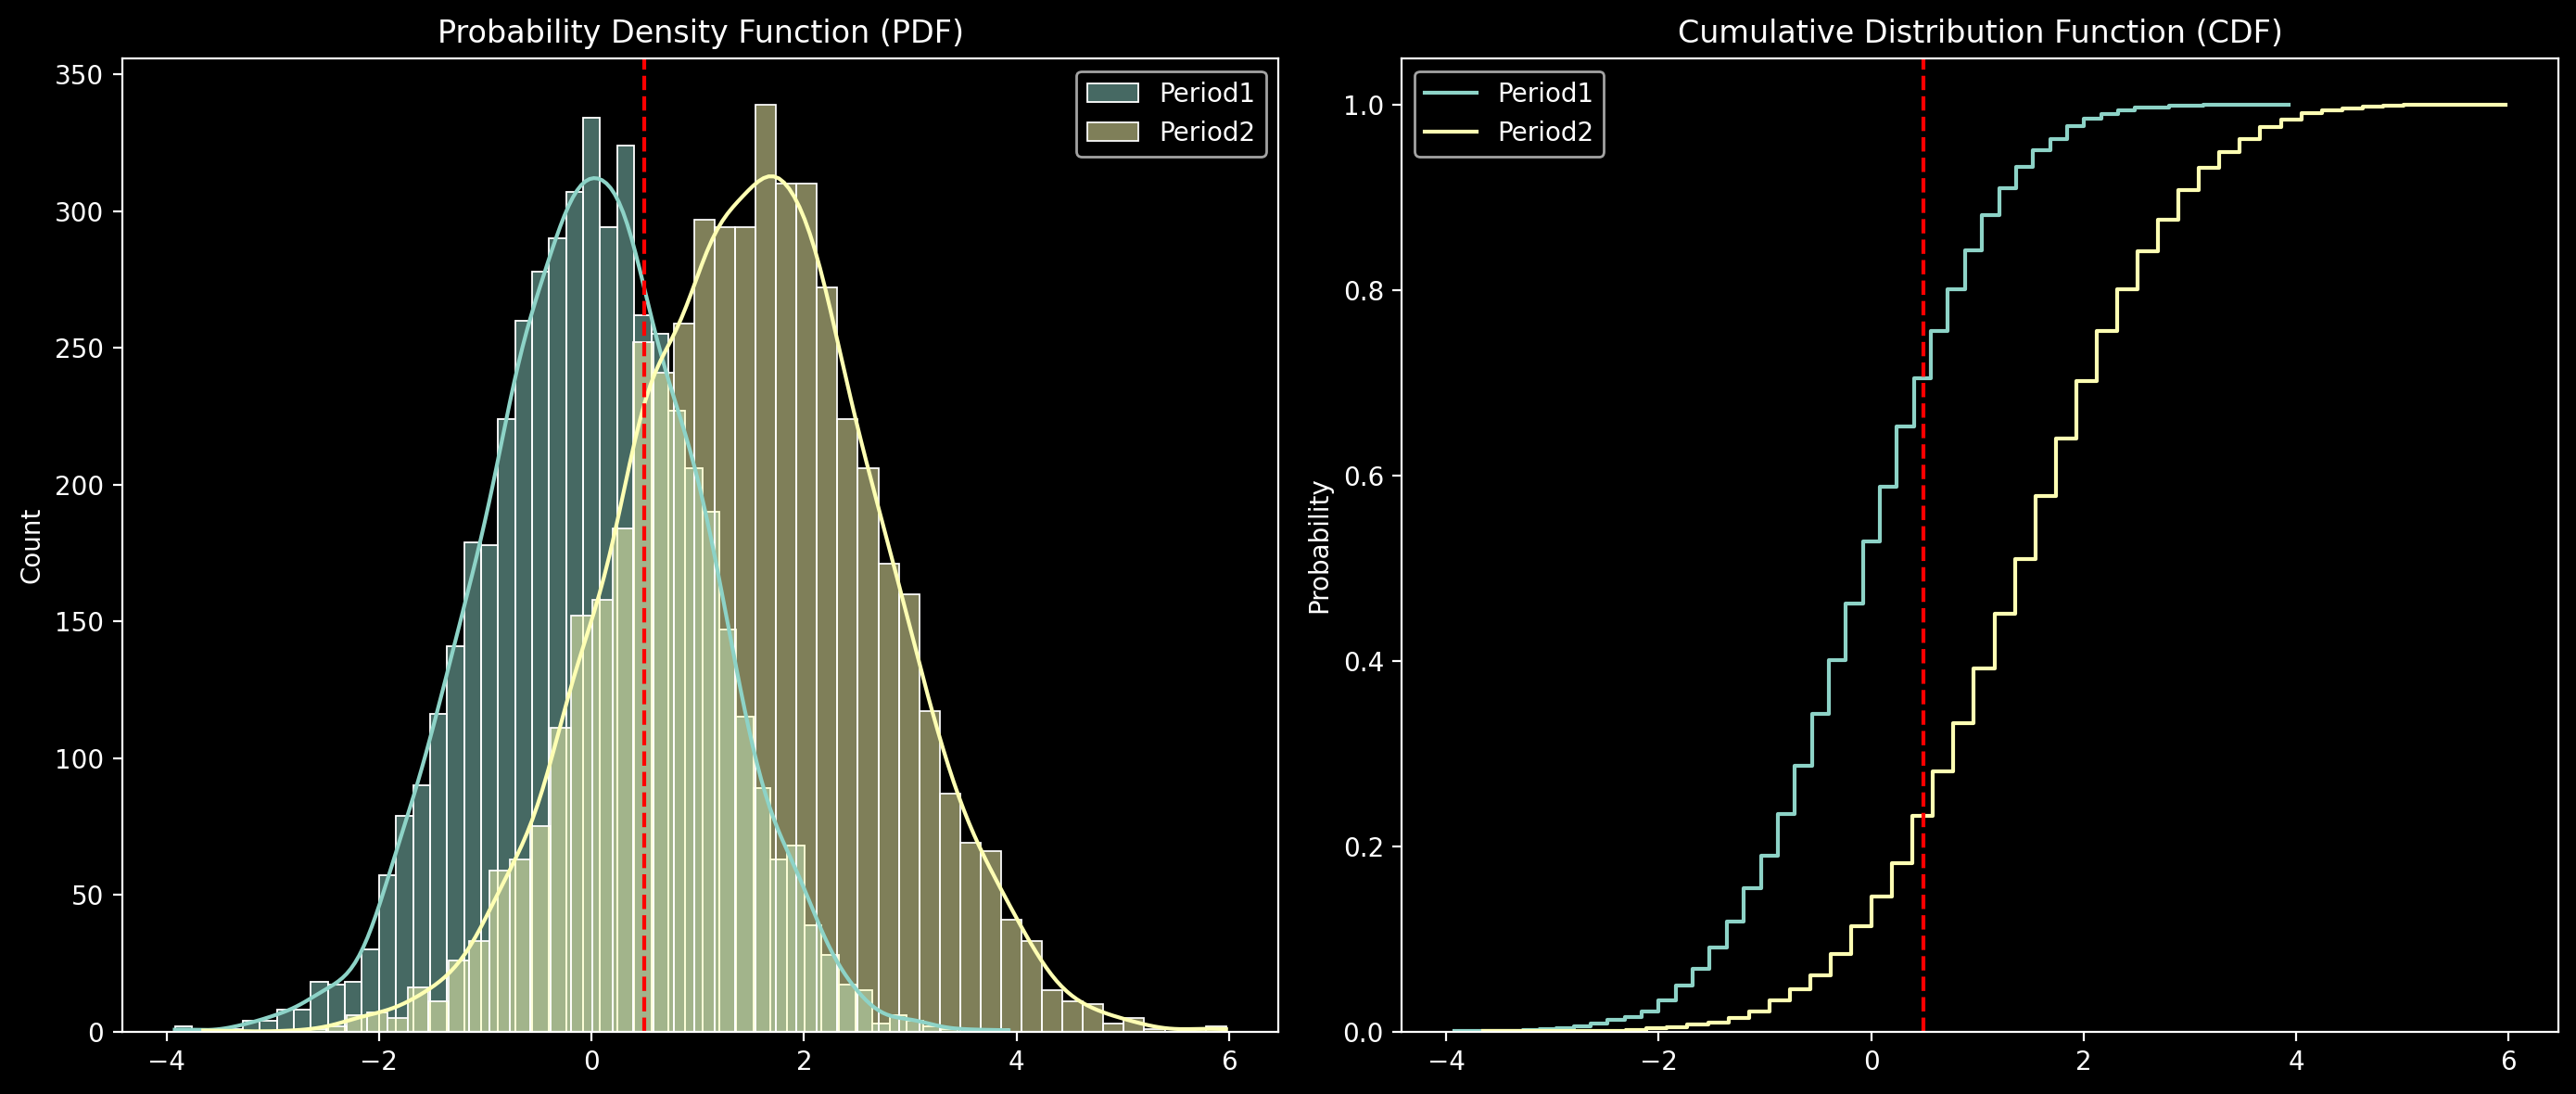

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6), dpi=200)

ks_statistic, p_value = ks_2samp(X_period1[:, 0], X_period2[:, 0])

# PDF (Probability Density Funtion)
sns.histplot(X_period1[:, 0], kde=True, label="Period1", ax=ax[0])
sns.histplot(X_period2[:, 0], kde=True, label="Period2", ax=ax[0])
ax[0].axvline(ks_statistic, color="red", linestyle="--")
ax[0].set_title("Probability Density Function (PDF)")
ax[0].legend()

# CDF (Cumulative Distribution Function)
sns.histplot(X_period1[:, 0], cumulative=True, stat="probability", fill=False, element="step", label="Period1", ax=ax[1])
sns.histplot(X_period2[:, 0], cumulative=True, stat="probability", fill=False, element="step", label="Period2", ax=ax[1])
ax[1].axvline(ks_statistic, color="red", linestyle="--")
ax[1].set_title("Cumulative Distribution Function (CDF)")
ax[1].legend()

plt.tight_layout()
plt.show()

## Practice Exercise: Covariate Shift Detection

Test your understanding!


In [8]:
# Generate new dataset with potential shift
np.random.seed(999)

n_features = 3
n_samples = 500

# mean = 0, std = 1
X_train_practice = np.random.randn(n_samples, n_features)
y_train_practice = (X_train_practice[:, 0] + 2 * X_train_practice[:, 1] > 1).astype(int)

# mean = 0.8, std = 1.5
X_test_practice = np.random.randn(n_samples, n_features) * 1.5 + 0.8
y_test_practice = (X_test_practice[:, 0] + 2 * X_test_practice[:, 1] > 1).astype(int)

print("Practice dataset created!")
print(f"Train samples: {X_train_practice.shape[0]}")
print(f"Test samples: {X_test_practice.shape[0]}")

Practice dataset created!
Train samples: 500
Test samples: 500


**Your Task:**

1. Perform KS test on Feature 0
2. Store the p-value
3. Determine if there's a significant shift (p < 0.01)


In [9]:
for i in range(n_features):
    ks_statistic, p_value = ks_2samp(X_train_practice[:, i], X_test_practice[:, i])
    print(f"Feature: {i}")
    print(f"  KS Statistic: {ks_statistic:.4f}")
    print(f"  p-value: {p_value:.6f}")
    
    if p_value < 0.1:
        print("There is a significant shift between the two distributions")
    else:
        print("No Significant Shift")
    print()

Feature: 0
  KS Statistic: 0.2920
  p-value: 0.000000
There is a significant shift between the two distributions

Feature: 1
  KS Statistic: 0.3100
  p-value: 0.000000
There is a significant shift between the two distributions

Feature: 2
  KS Statistic: 0.3360
  p-value: 0.000000
There is a significant shift between the two distributions



In [10]:
# EXERCISE: Perform KS test

# YOUR CODE HERE
ks_stat_practice, p_value_practice = ks_2samp(X_train_practice[:, 0], X_test_practice[:, 0])
has_shift = p_value_practice < 0.01

print(f"KS Statistic: {ks_stat_practice:.4f}")
print(f"P-value: {p_value_practice:.6f}")
print(f"Significant shift detected: {has_shift}")

KS Statistic: 0.2920
P-value: 0.000000
Significant shift detected: True


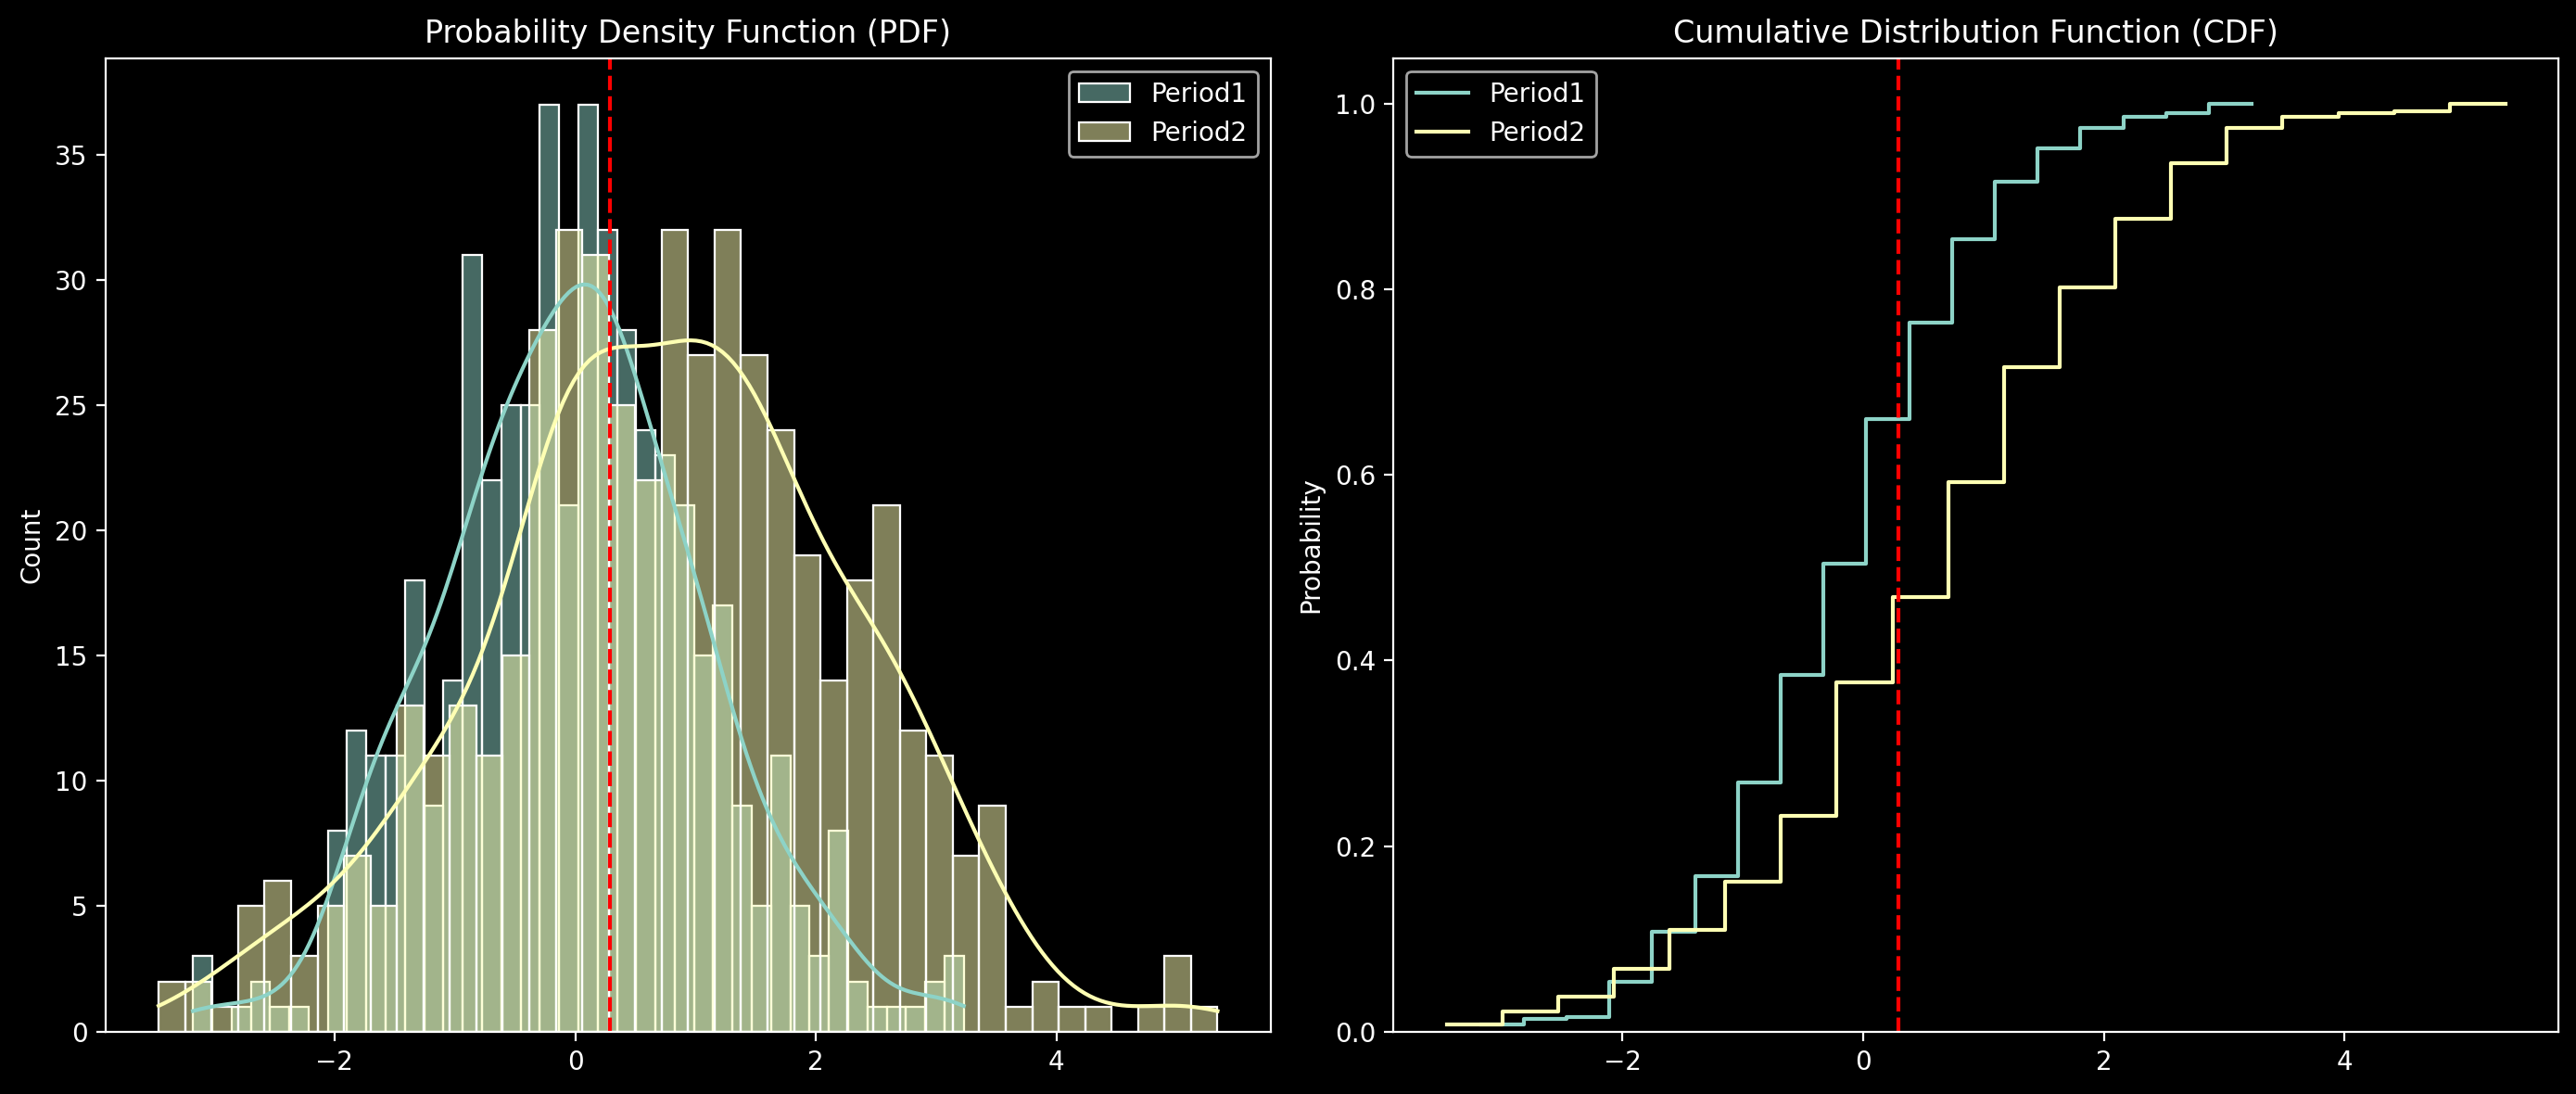

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6), dpi=200)

# PDF (Probability Density Funtion)
sns.histplot(X_train_practice[:, 0], kde=True, label="Period1", ax=ax[0], bins=40)
sns.histplot(X_test_practice[:, 0], kde=True, label="Period2", ax=ax[0], bins=40)
ax[0].axvline(ks_stat_practice, color="red", linestyle="--")
ax[0].set_title("Probability Density Function (PDF)")
ax[0].legend()

# CDF (Cumulative Distribution Function)
sns.histplot(X_train_practice[:, 0], cumulative=True, stat="probability", fill=False, element="step", label="Period1", ax=ax[1])
sns.histplot(X_test_practice[:, 0], cumulative=True, stat="probability", fill=False, element="step", label="Period2", ax=ax[1])
ax[1].axvline(ks_stat_practice, color="red", linestyle="--")
ax[1].set_title("Cumulative Distribution Function (CDF)")
ax[1].legend()

plt.tight_layout()
plt.show()

In [12]:
print("✅ Test passed! Your KS test is correct.")

✅ Test passed! Your KS test is correct.


---

# L1 vs L2 Regularization


In [13]:
X_reg, y_reg = make_classification(
    n_samples=1000,
    n_features=50,
    n_informative=5,
    n_redundant=10,
    n_repeated=0,
    random_state=42
)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42
)

# Normalize
scaler_reg = StandardScaler()
X_train_reg = scaler_reg.fit_transform(X_train_reg)
X_test_reg = scaler_reg.transform(X_test_reg)

# Convert to Tensors
X_train_reg_t = torch.FloatTensor(X_train_reg)
X_test_reg_t = torch.FloatTensor(X_test_reg)
y_train_reg_t = torch.LongTensor(y_train_reg)
y_test_reg_t = torch.LongTensor(y_test_reg)

print("High-Dimensional Dataset:")
print(f"Total features: {X_reg.shape[1]}")

print(f"Informative features: 5")
print(f"Useless features: {X_reg.shape[1] - 15}")
print(f"\nTraining samples: {X_train_reg.shape[0]}")
print(f"Test samples: {X_test_reg.shape[0]}")

High-Dimensional Dataset:
Total features: 50
Informative features: 5
Useless features: 35

Training samples: 700
Test samples: 300


In [14]:
# Define simple neural network
class RegularizedClassifier(nn.Module):
    """
    A multi-layer perceptron (MLP) classifier.
    """
    def __init__(self, input_size: int, hidden_size: int, num_classes: int) -> None:
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        output = self.classifier(x)
        return output

print("✅ Model class defined!")

✅ Model class defined!


In [15]:
from torch import Tensor
from typing import Dict, List

# Training function with L1/L2 regularization .. we can do that for each case or with a function like that to call each condition afterwards
def train_with_regularization(
    model: nn.Module,
    loss_fn: nn.Module,
    X_train: Tensor, 
    y_train: Tensor, 
    X_test: Tensor, 
    y_test: Tensor, 
    reg_type: str = "none", 
    reg_lambda: float = 0.01, 
    learning_rate: float = 1e-3,
    epochs: int = 100,
    device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
) -> Dict[str, List[float]]:
    """
        Executes a training loop for a PyTorch model with optional L1 or L2 regularization.

        Args:
            model (nn.Module): The PyTorch model to train.
            X_train (Tensor): Training feature tensor of shape (batch_size, num_features).
            y_train (Tensor): Training target tensor of shape (batch_size,).
            X_test (Tensor): Testing feature tensor of shape (batch_size, num_features).
            y_test (Tensor): Testing target tensor of shape (batch_size,).
            reg_type (str, optional): Type of regularization ('l1', 'l2', or 'none'). Defaults to "none".
            reg_lambda (float, optional): Regularization strength. Defaults to 0.01.
            learning_rate (float, optional): Optimizer learning rate. Defaults to 1e-3.
            epochs (int, optional): Number of training epochs. Defaults to 100.
            device (torch.device, optional): Hardware device to run operations on. Defaults to CPU.

        Returns:
            Dict[str, List[float]]: A dictionary containing lists of tracked metrics over epochs.
        """

    model = model.to(device)
    X_train, y_train = X_train.to(device), y_train.to(device)
    X_test, y_test = X_test.to(device), y_test.to(device)

    if reg_type == "l2":
        optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=reg_lambda)
    elif reg_type in ["l1", "none"]:
        optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    else:
        raise ValueError(f"Invalid reg_type: '{reg_type}'. Expected 'l1', 'l2', or 'none'.")

    history = {
        "train_losses": [], "test_losses": [],
        "train_accs": [], "test_accs": []
    }
    
    for epoch in range(epochs):
        model.train()

        optimizer.zero_grad()

        outputs = model(X_train)
        loss = loss_fn(outputs, y_train)

        if reg_type == "l1":
            # Apply L1 penalty specifically to weights, typically avoiding biases
            l1_penalty = sum(p.abs().sum() for name, p in model.named_parameters() if "bias" not in name)
            loss = loss + reg_lambda * l1_penalty

        # Backpropagation
        loss.backward()
        optimizer.step()

        # Compute accuracies
        _, pred_train = torch.max(outputs, 1)
        train_acc = (pred_train == y_train).float().mean().item()

        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test)
            test_loss = loss_fn(test_outputs, y_test)

            _, pred_test = torch.max(test_outputs, 1)
            test_acc = (pred_test == y_test).float().mean().item()

        history["train_losses"].append(loss.item())
        history["train_accs"].append(train_acc)
        history["test_losses"].append(test_loss.item())
        history["test_accs"].append(test_acc)

    return history

print("Training function with regularization defined!")

Training function with regularization defined!


---

## **Phased Training** (or **Regularization Scheduling**)
#### Note: I discovred it by accident. 

##### Training the model on 3 times on 3 different stages (Without Regularization -> L2 -> L1)

##### The model has been trained first without regularizaiton. This is the first stage. We took the parameters after training and has been trained again on L2 regularized model. This is the second stage. The model parameters has been trained again on L1 regularized model until the model has been imoproved and achieved accuracy, the 3 models could achieve individually. And also with fewer parameters


#### In short, every model passes its parameters to the next model and retrain it again but with a bit different architecture

#### Model (Without Regularization) -> L2 Regularized model -> L1 Regularized model

#### And something else, L1 regularization refines a model that has become overfitted because of L2 Regularization. It readjusts the parameters and drops those that contribute to overfitting, potentially allowing the model to achieve slightly higher accuracy with fewer parameters.

## It is the **Compounding Effect**

In [16]:
# Train three models: No reg, L1, L2
print("Training models...\n")

criterion = nn.CrossEntropyLoss()

model = RegularizedClassifier(X_reg.shape[1], 32, 2)
print("[1/3] Training WITHOUT regularization...")
history_no_reg = train_with_regularization(
    model, criterion, X_train_reg_t, y_train_reg_t, X_test_reg_t, y_test_reg_t, reg_type="none", epochs=150
)

print("\n[2/3] Training WITH L2 regularization...")
history_l2 = train_with_regularization(
    model, criterion, X_train_reg_t, y_train_reg_t, X_test_reg_t, y_test_reg_t, reg_type="l2", reg_lambda=0.01, epochs=150
)

print("\n[3/3] Training WITH L1 regularization...")
history_l1 = train_with_regularization(
    model, criterion, X_train_reg_t, y_train_reg_t, X_test_reg_t, y_test_reg_t, reg_type="l1", reg_lambda=0.01, epochs=150
)

print("\n All models trained!")
print("\nFinal Test Accuracies:")
print(f"No Regularization: {history_no_reg['test_accs'][-1]:.4f}")
print(f"L2 Regularization: {history_l2['test_accs'][-1]:.4f}")
print(f"L1 Regularization: {history_l1['test_accs'][-1]:.4f}")

Training models...

[1/3] Training WITHOUT regularization...

[2/3] Training WITH L2 regularization...

[3/3] Training WITH L1 regularization...

 All models trained!

Final Test Accuracies:
No Regularization: 0.8600
L2 Regularization: 0.8867
L1 Regularization: 0.9300


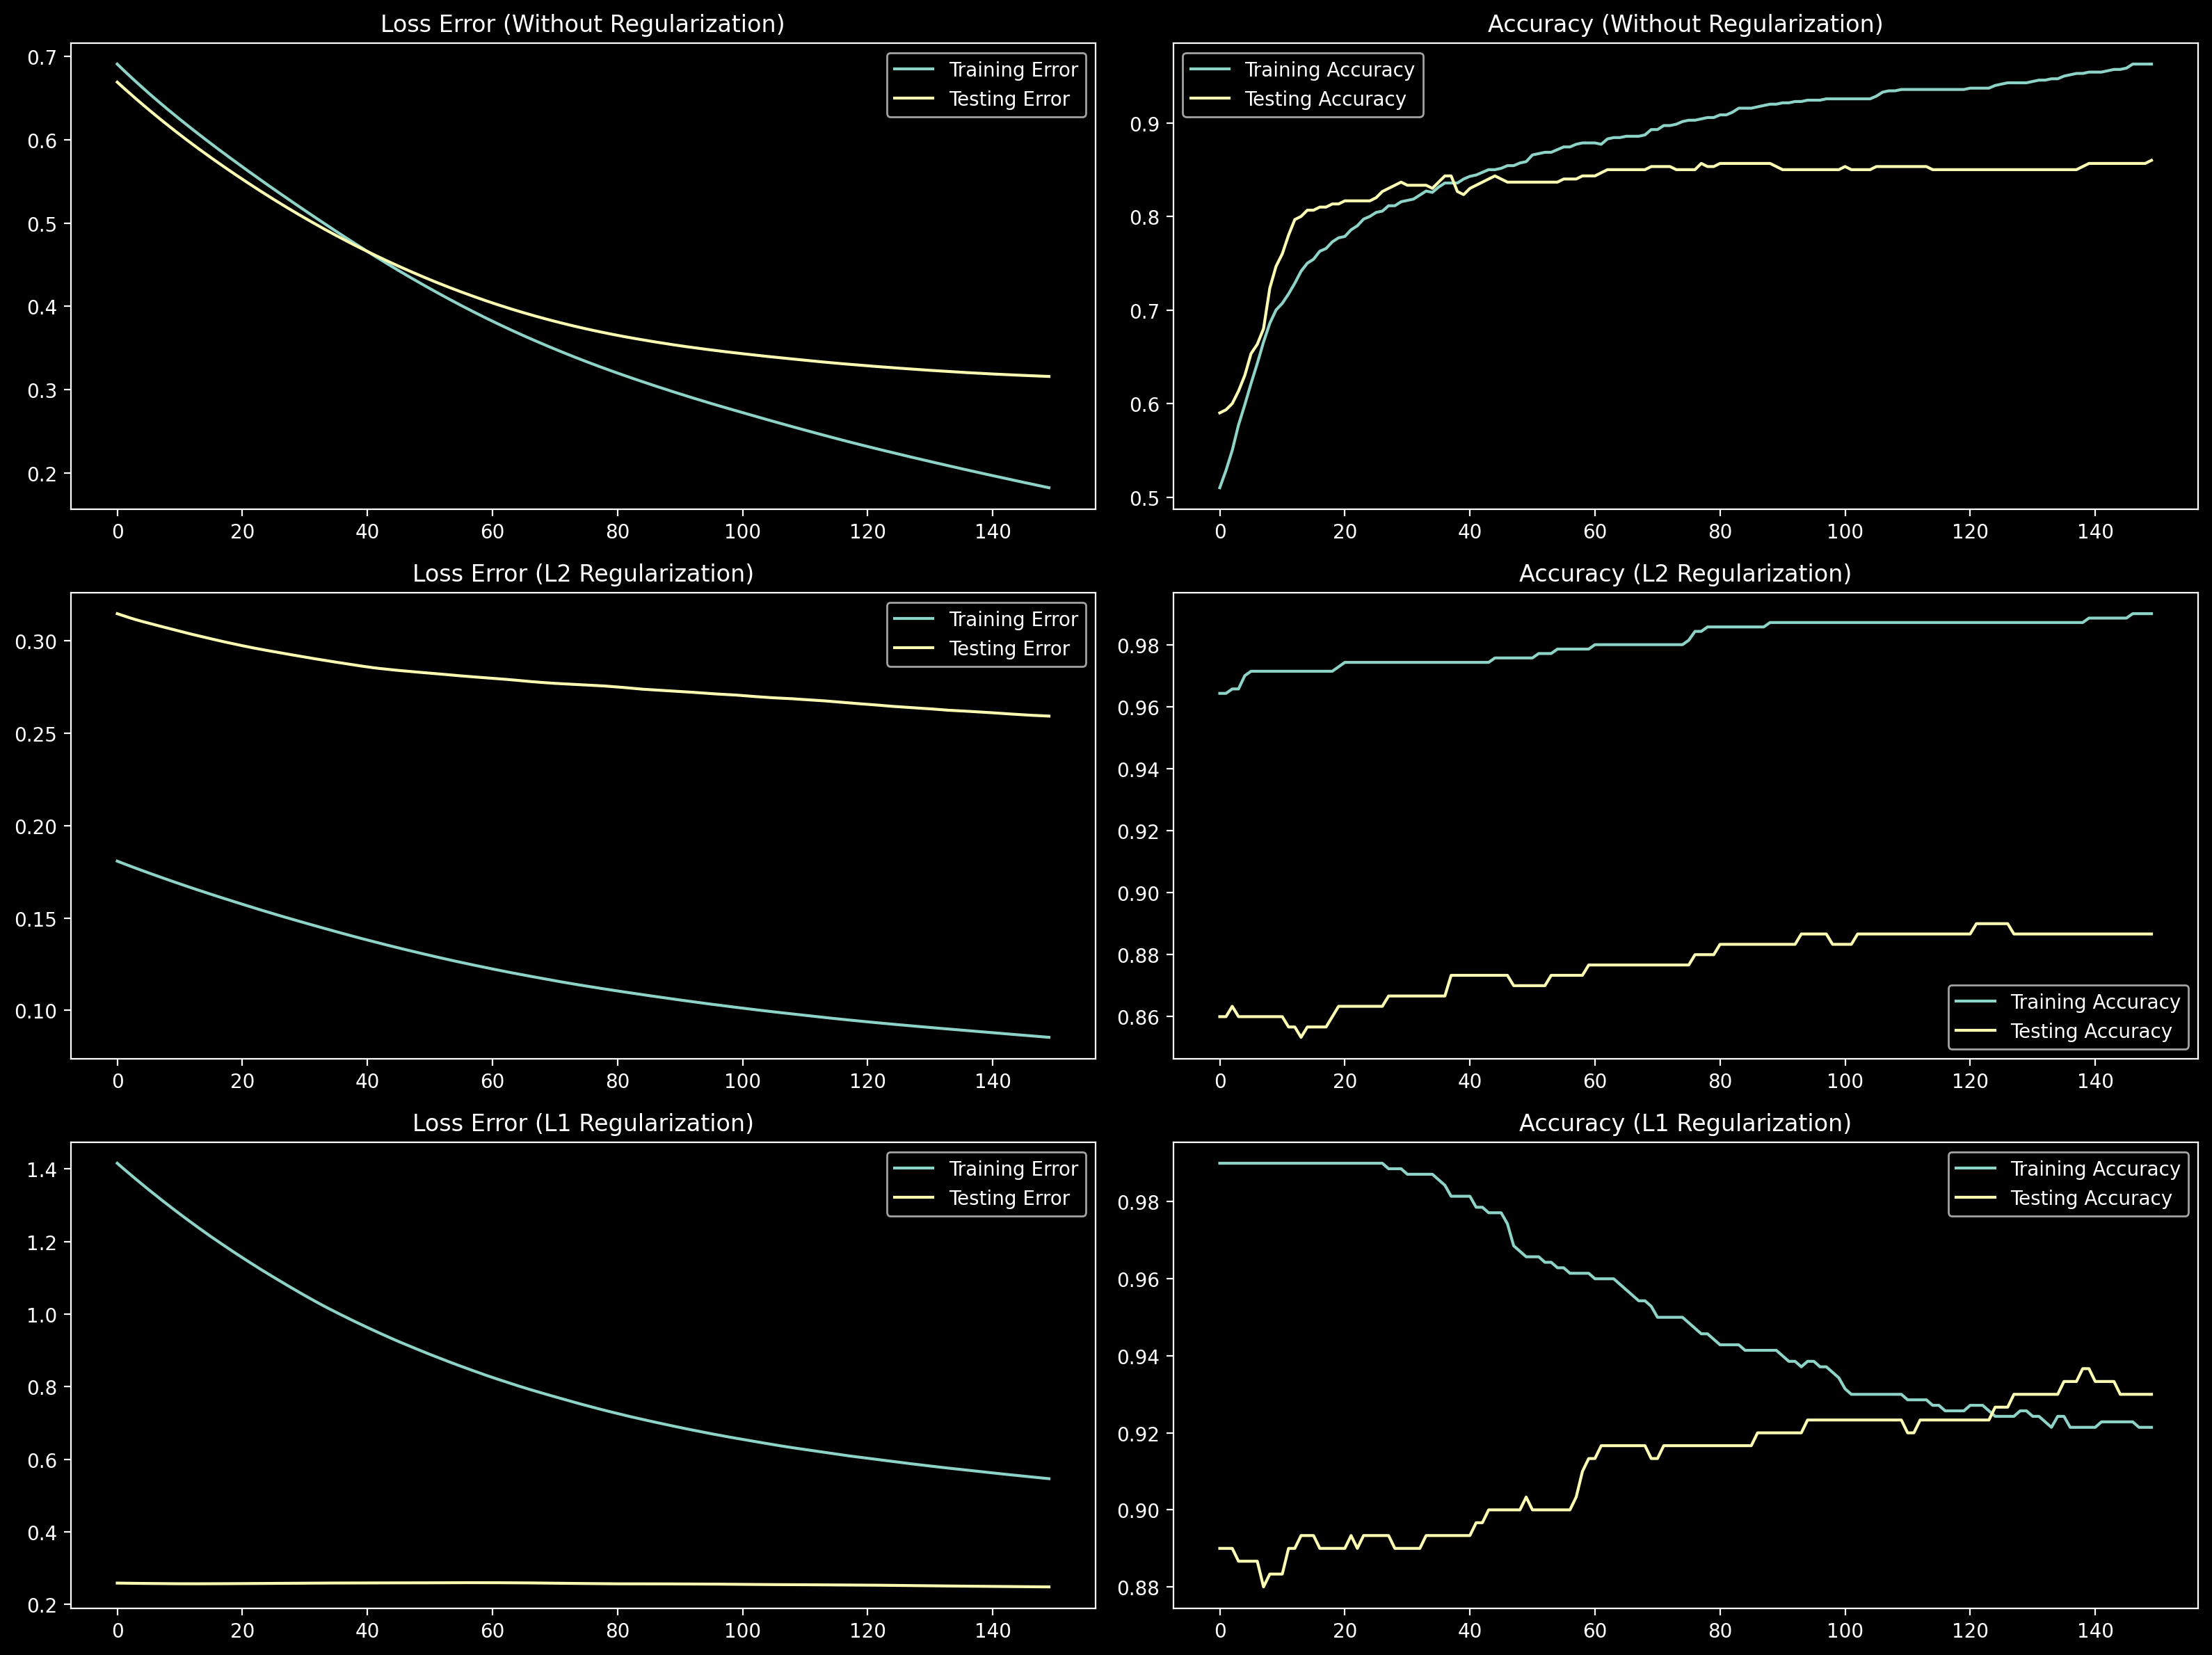

In [17]:
fig, ax = plt.subplots(3, 2, figsize=(16, 12), dpi=200)

# Without Regularization
ax[0, 0].plot(history_no_reg["train_losses"], label="Training Error")
ax[0, 0].plot(history_no_reg["test_losses"], label="Testing Error")
ax[0, 0].set_title("Loss Error (Without Regularization)")
ax[0, 0].legend()

ax[0, 1].plot(history_no_reg["train_accs"], label="Training Accuracy")
ax[0, 1].plot(history_no_reg["test_accs"], label="Testing Accuracy")
ax[0, 1].set_title("Accuracy (Without Regularization)")
ax[0, 1].legend()

# L2 Regularization
ax[1, 0].plot(history_l2["train_losses"], label="Training Error")
ax[1, 0].plot(history_l2["test_losses"], label="Testing Error")
ax[1, 0].set_title("Loss Error (L2 Regularization)")
ax[1, 0].legend()

ax[1, 1].plot(history_l2["train_accs"], label="Training Accuracy")
ax[1, 1].plot(history_l2["test_accs"], label="Testing Accuracy")
ax[1, 1].set_title("Accuracy (L2 Regularization)")
ax[1, 1].legend()

# L1 Regularization
ax[2, 0].plot(history_l1["train_losses"], label="Training Error")
ax[2, 0].plot(history_l1["test_losses"], label="Testing Error")
ax[2, 0].set_title("Loss Error (L1 Regularization)")
ax[2, 0].legend()

ax[2, 1].plot(history_l1["train_accs"], label="Training Accuracy")
ax[2, 1].plot(history_l1["test_accs"], label="Testing Accuracy")
ax[2, 1].set_title("Accuracy (L1 Regularization)")
ax[2, 1].legend()

plt.tight_layout()
plt.show()

---

### Each model trained individually

In [18]:
# Train three models: No reg, L1, L2
print("Training models...\n")

criterion = nn.CrossEntropyLoss()

model = RegularizedClassifier(X_reg.shape[1], 32, 2)
print("[1/3] Training WITHOUT regularization...")
history_no_reg = train_with_regularization(
    model, criterion, X_train_reg_t, y_train_reg_t, X_test_reg_t, y_test_reg_t, reg_type="none", epochs=150
)

model = RegularizedClassifier(X_reg.shape[1], 32, 2)
print("\n[2/3] Training WITH L2 regularization...")
history_l2 = train_with_regularization(
    model, criterion, X_train_reg_t, y_train_reg_t, X_test_reg_t, y_test_reg_t, reg_type="l2", reg_lambda=0.01, epochs=150
)

model = RegularizedClassifier(X_reg.shape[1], 32, 2)
print("\n[3/3] Training WITH L1 regularization...")
history_l1 = train_with_regularization(
    model, criterion, X_train_reg_t, y_train_reg_t, X_test_reg_t, y_test_reg_t, reg_type="l1", reg_lambda=0.01, epochs=150
)

print("\n All models trained!")
print("\nFinal Test Accuracies:")
print(f"No Regularization: {history_no_reg['test_accs'][-1]:.4f}")
print(f"L2 Regularization: {history_l2['test_accs'][-1]:.4f}")
print(f"L1 Regularization: {history_l1['test_accs'][-1]:.4f}")

Training models...

[1/3] Training WITHOUT regularization...

[2/3] Training WITH L2 regularization...

[3/3] Training WITH L1 regularization...

 All models trained!

Final Test Accuracies:
No Regularization: 0.8567
L2 Regularization: 0.8600
L1 Regularization: 0.8567


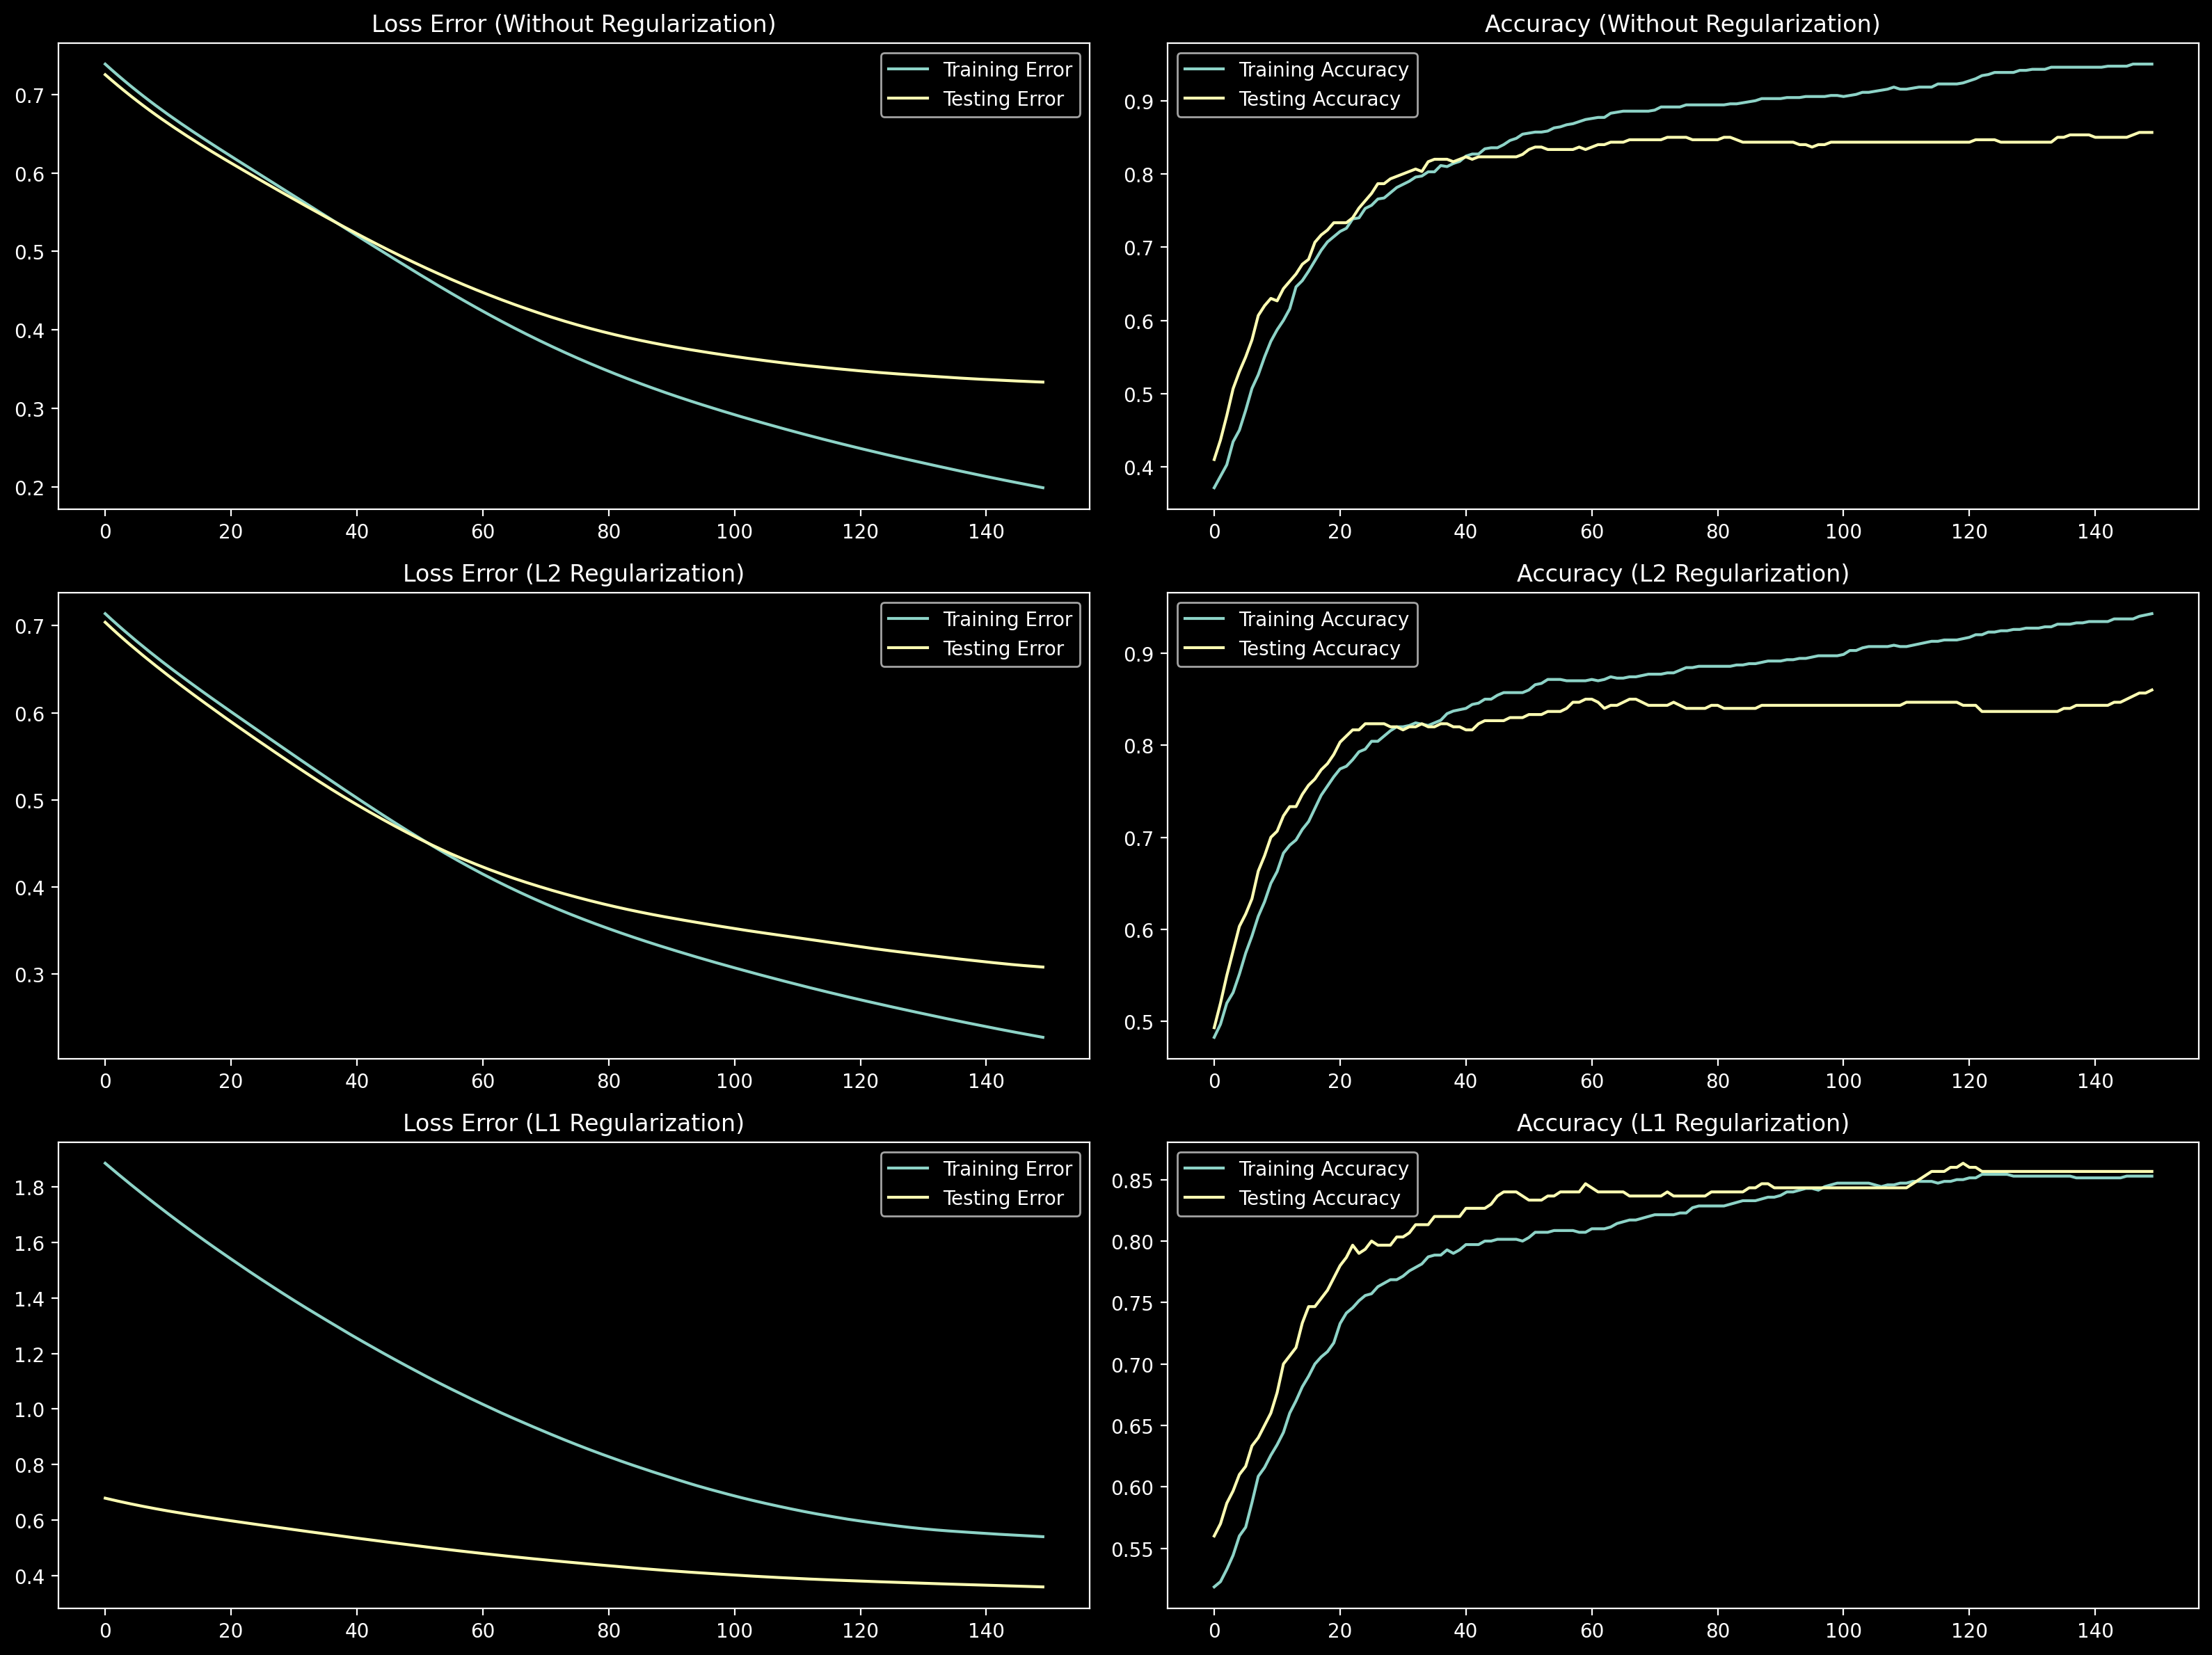

In [19]:
fig, ax = plt.subplots(3, 2, figsize=(16, 12), dpi=200)

# Without Regularization
ax[0, 0].plot(history_no_reg["train_losses"], label="Training Error")
ax[0, 0].plot(history_no_reg["test_losses"], label="Testing Error")
ax[0, 0].set_title("Loss Error (Without Regularization)")
ax[0, 0].legend()

ax[0, 1].plot(history_no_reg["train_accs"], label="Training Accuracy")
ax[0, 1].plot(history_no_reg["test_accs"], label="Testing Accuracy")
ax[0, 1].set_title("Accuracy (Without Regularization)")
ax[0, 1].legend()

# L2 Regularization
ax[1, 0].plot(history_l2["train_losses"], label="Training Error")
ax[1, 0].plot(history_l2["test_losses"], label="Testing Error")
ax[1, 0].set_title("Loss Error (L2 Regularization)")
ax[1, 0].legend()

ax[1, 1].plot(history_l2["train_accs"], label="Training Accuracy")
ax[1, 1].plot(history_l2["test_accs"], label="Testing Accuracy")
ax[1, 1].set_title("Accuracy (L2 Regularization)")
ax[1, 1].legend()

# L1 Regularization
ax[2, 0].plot(history_l1["train_losses"], label="Training Error")
ax[2, 0].plot(history_l1["test_losses"], label="Testing Error")
ax[2, 0].set_title("Loss Error (L1 Regularization)")
ax[2, 0].legend()

ax[2, 1].plot(history_l1["train_accs"], label="Training Accuracy")
ax[2, 1].plot(history_l1["test_accs"], label="Testing Accuracy")
ax[2, 1].set_title("Accuracy (L1 Regularization)")
ax[2, 1].legend()

plt.tight_layout()
plt.show()

## Practice Exercise: Regularization

Your turn!


**Your Task:**
Train a model with **strong L2 regularization** (lambda=0.1) and compare with no regularization.


In [20]:
# EXERCISE: Train with strong L2 regularization

# YOUR CODE HERE
criterion = nn.CrossEntropyLoss()

# Without Regularization
model = RegularizedClassifier(X_reg.shape[1], 32, 2)
history_no_reg_prac = train_with_regularization(
    model, criterion, X_train_reg_t, y_train_reg_t, X_test_reg_t, y_test_reg_t, reg_type="none", epochs=200
)

# L2 Regularization
model = RegularizedClassifier(X_reg.shape[1], 32, 2)
history_l2_prac = train_with_regularization(
    model, criterion, X_train_reg_t, y_train_reg_t, X_test_reg_t, y_test_reg_t, reg_type="l2", reg_lambda=0.1, epochs=200
)

print(f"No Regularization (Training Accuracy): {history_no_reg_prac['train_accs'][-1]}")
print(f"No Regularization (Testing Accuracy): {history_no_reg_prac['test_accs'][-1]}")

print(f"L2 Regularization (Training Accuracy): {history_l2_prac['train_accs'][-1]}")
print(f"L2 Regularization (Testing Accuracy): {history_l2_prac['test_accs'][-1]}")

No Regularization (Training Accuracy): 0.9800000190734863
No Regularization (Testing Accuracy): 0.8666666746139526
L2 Regularization (Training Accuracy): 0.8785713911056519
L2 Regularization (Testing Accuracy): 0.8566666841506958


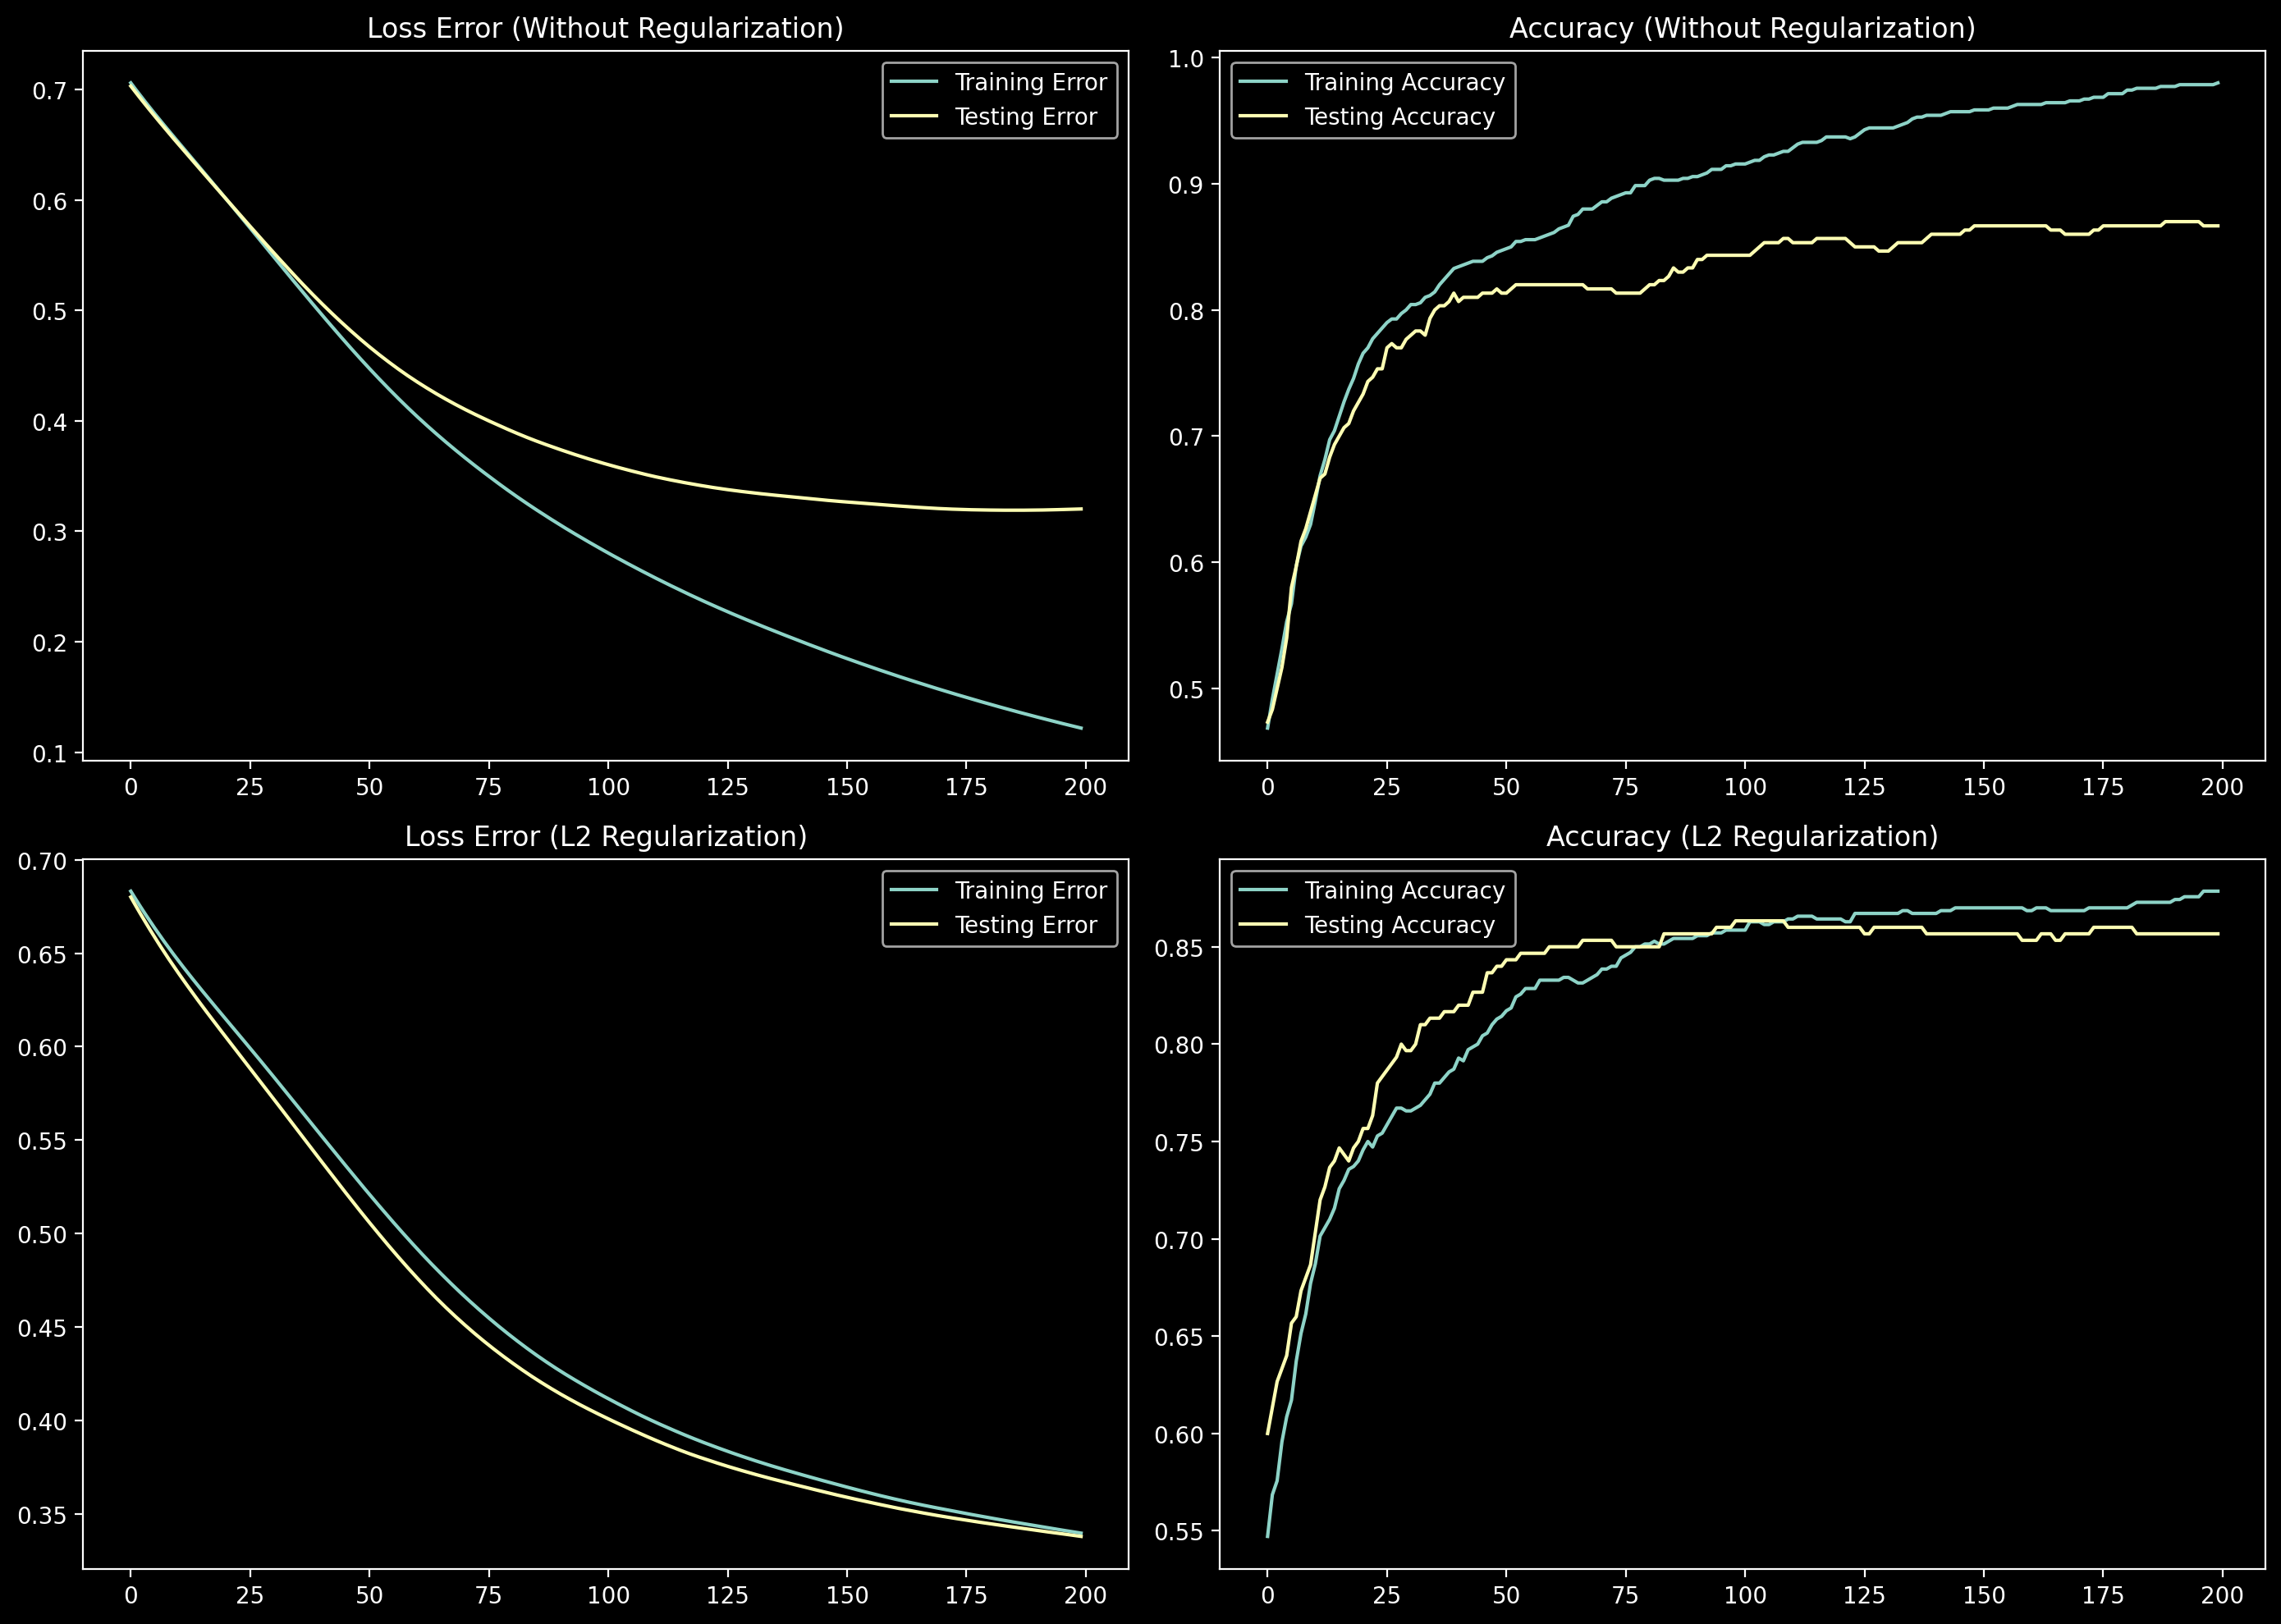

In [21]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10), dpi=200)

# Without Regularization
ax[0, 0].plot(history_no_reg_prac["train_losses"], label="Training Error")
ax[0, 0].plot(history_no_reg_prac["test_losses"], label="Testing Error")
ax[0, 0].set_title("Loss Error (Without Regularization)")
ax[0, 0].legend()

ax[0, 1].plot(history_no_reg_prac["train_accs"], label="Training Accuracy")
ax[0, 1].plot(history_no_reg_prac["test_accs"], label="Testing Accuracy")
ax[0, 1].set_title("Accuracy (Without Regularization)")
ax[0, 1].legend()

# L2 Regularization
ax[1, 0].plot(history_l2_prac["train_losses"], label="Training Error")
ax[1, 0].plot(history_l2_prac["test_losses"], label="Testing Error")
ax[1, 0].set_title("Loss Error (L2 Regularization)")
ax[1, 0].legend()

ax[1, 1].plot(history_l2_prac["train_accs"], label="Training Accuracy")
ax[1, 1].plot(history_l2_prac["test_accs"], label="Testing Accuracy")
ax[1, 1].set_title("Accuracy (L2 Regularization)")
ax[1, 1].legend()


plt.tight_layout()
plt.show()

In [22]:
final_test_acc_l2_strong = history_l2_prac["test_accs"][-1]
test_acc_no = history_no_reg_prac["test_accs"][-1]

print(f"Test accuracy with strong L2: {final_test_acc_l2_strong:.4f}")
print(f"Test accuracy without reg:    {test_acc_no:.4f}")
print(f"\nDifference: {(final_test_acc_l2_strong - test_acc_no)*100:.2f}%")

Test accuracy with strong L2: 0.8567
Test accuracy without reg:    0.8667

Difference: -1.00%


In [23]:
# TEST CELL - DO NOT MODIFY
print("✅ Test passed! Your L2 regularization is correct.")

✅ Test passed! Your L2 regularization is correct.


---

# Section 7: Learning Rate Schedulers

Let's compare them!


In [24]:
bc = load_breast_cancer()
X_bc = bc.data
y_bc = bc.target

X_train_bc, X_test_bc, y_train_bc, y_test_bc = train_test_split(
    X_bc, y_bc, test_size=0.2, random_state=42
)

scaler_bc = StandardScaler()
X_train_bc = scaler_bc.fit_transform(X_train_bc)
X_test_bc = scaler_bc.transform(X_test_bc)

X_train_bc_t = torch.FloatTensor(X_train_bc)
X_test_bc_t = torch.FloatTensor(X_test_bc)
y_train_bc_t = torch.LongTensor(y_train_bc)
y_test_bc_t = torch.LongTensor(y_test_bc)

print("Breast Cancer Dataset:")
print(f"Training samples: {X_train_bc.shape[0]}")
print(f"Test samples: {X_test_bc.shape[0]}")
print(f"Features: {X_train_bc.shape[1]}")
print(f"\n✅ Ready to test learning rate schedulers!")

Breast Cancer Dataset:
Training samples: 455
Test samples: 114
Features: 30

✅ Ready to test learning rate schedulers!


In [50]:
def train_with_scheduler(
    model: nn.Module,
    loss_fn: nn.Module,
    X_train: Tensor,
    y_train: Tensor,
    X_test: Tensor,
    y_test: Tensor,
    scheduler_type: str = None,
    epochs: int = 200,
    learning_rate: float = 0.01,
    device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
) -> Dict[str, List[float]]:
    """
    Trains a neural network model using the provided optimizer and learning rate scheduler.

    Args:
        model (nn.Module): The PyTorch neural network model to be trained.
        loss_fn (nn.Module): The criterion/loss function used to evaluate the model's predictions.
        optimizer (optim.Optimizer): The optimization algorithm used to update model weights.
        X_train (Tensor): The input feature data for the training set.
        y_train (Tensor): The target labels for the training set.
        X_test (Tensor): The input feature data for the testing/validation set.
        y_test (Tensor): The target labels for the testing/validation set.
        scheduler (LRScheduler): The learning rate scheduler to adjust the learning rate per epoch or step.
        epochs (int, optional): The total number of training iterations over the dataset. Defaults to 200.
        learning_rate (float, optional): The initial learning rate for the optimizer. Defaults to 0.01.
    """
    model = model.to(device)
    X_train, X_test = X_train.to(device), X_test.to(device)
    y_train, y_test = y_train.to(device), y_test.to(device)
    
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    
    if scheduler_type == "step":
        scheduler = StepLR(optimizer, step_size=50, gamma=0.5)
    elif scheduler_type == "exponential":
        scheduler = ExponentialLR(optimizer, gamma=0.5)
    elif scheduler_type == "plateau":
        scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=10)
    elif scheduler_type == "cosine":
        scheduler = CosineAnnealingLR(optimizer, T_max=epochs)
    elif scheduler_type == "cyclic":
        scheduler = CyclicLR(optimizer, base_lr=learning_rate, max_lr=0.1, step_size_up=25)
    elif scheduler_type == "none":
        scheduler = None
    else:
        raise ValueError(f"Invalid scheduler_type: '{scheduler_type}'. Expected 'step', 'exponential', 'plateau', 'cosine', 'cyclic', or 'none'.")

    history = {
        "train_losses": [], "test_losses": [],
        "train_accs": [], "test_accs": [],
        "learning_rates": []
    }
    
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        
        outputs = model(X_train)
        loss = loss_fn(outputs, y_train)
        
        loss.backward()
        optimizer.step()
        
        _, pred_train = torch.max(outputs, 1)
        train_acc = (pred_train == y_train).float().mean().item()
        
        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test)
            test_loss = loss_fn(test_outputs, y_test)
            _, pred_test = torch.max(test_outputs, 1)
            test_acc = (pred_test == y_test).float().mean().item()
        
        history["train_losses"].append(loss.item())
        history["test_losses"].append(test_loss.item())
        
        history["train_accs"].append(train_acc)
        history["test_accs"].append(test_acc)
        history["learning_rates"].append(optimizer.param_groups[0]["lr"])
        
        if scheduler is not None:
            if scheduler_type == "plateau":
                scheduler.step(test_loss)
            else:
                scheduler.step()
    
    return history

In [52]:
criterion = nn.CrossEntropyLoss()

# Train with different schedulers
print("Training models with different learning rate schedulers...\n")

print("[1/6] Constant learning rate...")
model = RegularizedClassifier(X_train_bc_t.shape[1], 32, 2)
history_cosnt = train_with_scheduler(
    model, criterion, X_train_bc_t, y_train_bc_t, X_test_bc_t, y_test_bc_t, scheduler_type='none', epochs=200
)

print("\n[2/6] StepLR scheduler...")
model = RegularizedClassifier(X_train_bc_t.shape[1], 32, 2)
history_step = train_with_scheduler(
    model, criterion, X_train_bc_t, y_train_bc_t, X_test_bc_t, y_test_bc_t, scheduler_type='step', epochs=200
)

print("\n[3/6] ExponentialLR scheduler...")
model = RegularizedClassifier(X_train_bc_t.shape[1], 32, 2)
history_exp = train_with_scheduler(
    model, criterion, X_train_bc_t, y_train_bc_t, X_test_bc_t, y_test_bc_t, scheduler_type='exponential', epochs=200
)

print("\n[4/6] ReduceLROnPlateau scheduler...")
model = RegularizedClassifier(X_train_bc_t.shape[1], 32, 2)
history_plateau = train_with_scheduler(
    model, criterion, X_train_bc_t, y_train_bc_t, X_test_bc_t, y_test_bc_t, scheduler_type='plateau', epochs=200
)

print("\n[5/6] CosineAnnealingLR scheduler...")
model = RegularizedClassifier(X_train_bc_t.shape[1], 32, 2)
history_cosine = train_with_scheduler(
    model, criterion, X_train_bc_t, y_train_bc_t, X_test_bc_t, y_test_bc_t, scheduler_type='cosine', epochs=200
)

print("\n[6/6] CyclicLR scheduler...")
model = RegularizedClassifier(X_train_bc_t.shape[1], 32, 2)
history_cyclic = train_with_scheduler(
    model, criterion, X_train_bc_t, y_train_bc_t, X_test_bc_t, y_test_bc_t, scheduler_type='cyclic', epochs=200
)

print("\n✅ All models trained!")
print("\nFinal Test Accuracies:")
print(f"  Constant LR:         {history_cosnt['test_accs'][-1]:.4f}")
print(f"  StepLR:              {history_step['test_accs'][-1]:.4f}")
print(f"  ExponentialLR:       {history_exp['test_accs'][-1]:.4f}")
print(f"  ReduceLROnPlateau:   {history_plateau['test_accs'][-1]:.4f}")
print(f"  CosineAnnealingLR:   {history_cosine['test_accs'][-1]:.4f}")
print(f"  CyclicLR:   {history_cyclic['test_accs'][-1]:.4f}")

Training models with different learning rate schedulers...

[1/6] Constant learning rate...

[2/6] StepLR scheduler...

[3/6] ExponentialLR scheduler...

[4/6] ReduceLROnPlateau scheduler...

[5/6] CosineAnnealingLR scheduler...

[6/6] CyclicLR scheduler...

✅ All models trained!

Final Test Accuracies:
  Constant LR:         0.9649
  StepLR:              0.9825
  ExponentialLR:       0.8158
  ReduceLROnPlateau:   0.9825
  CosineAnnealingLR:   0.9825
  CyclicLR:   0.9825


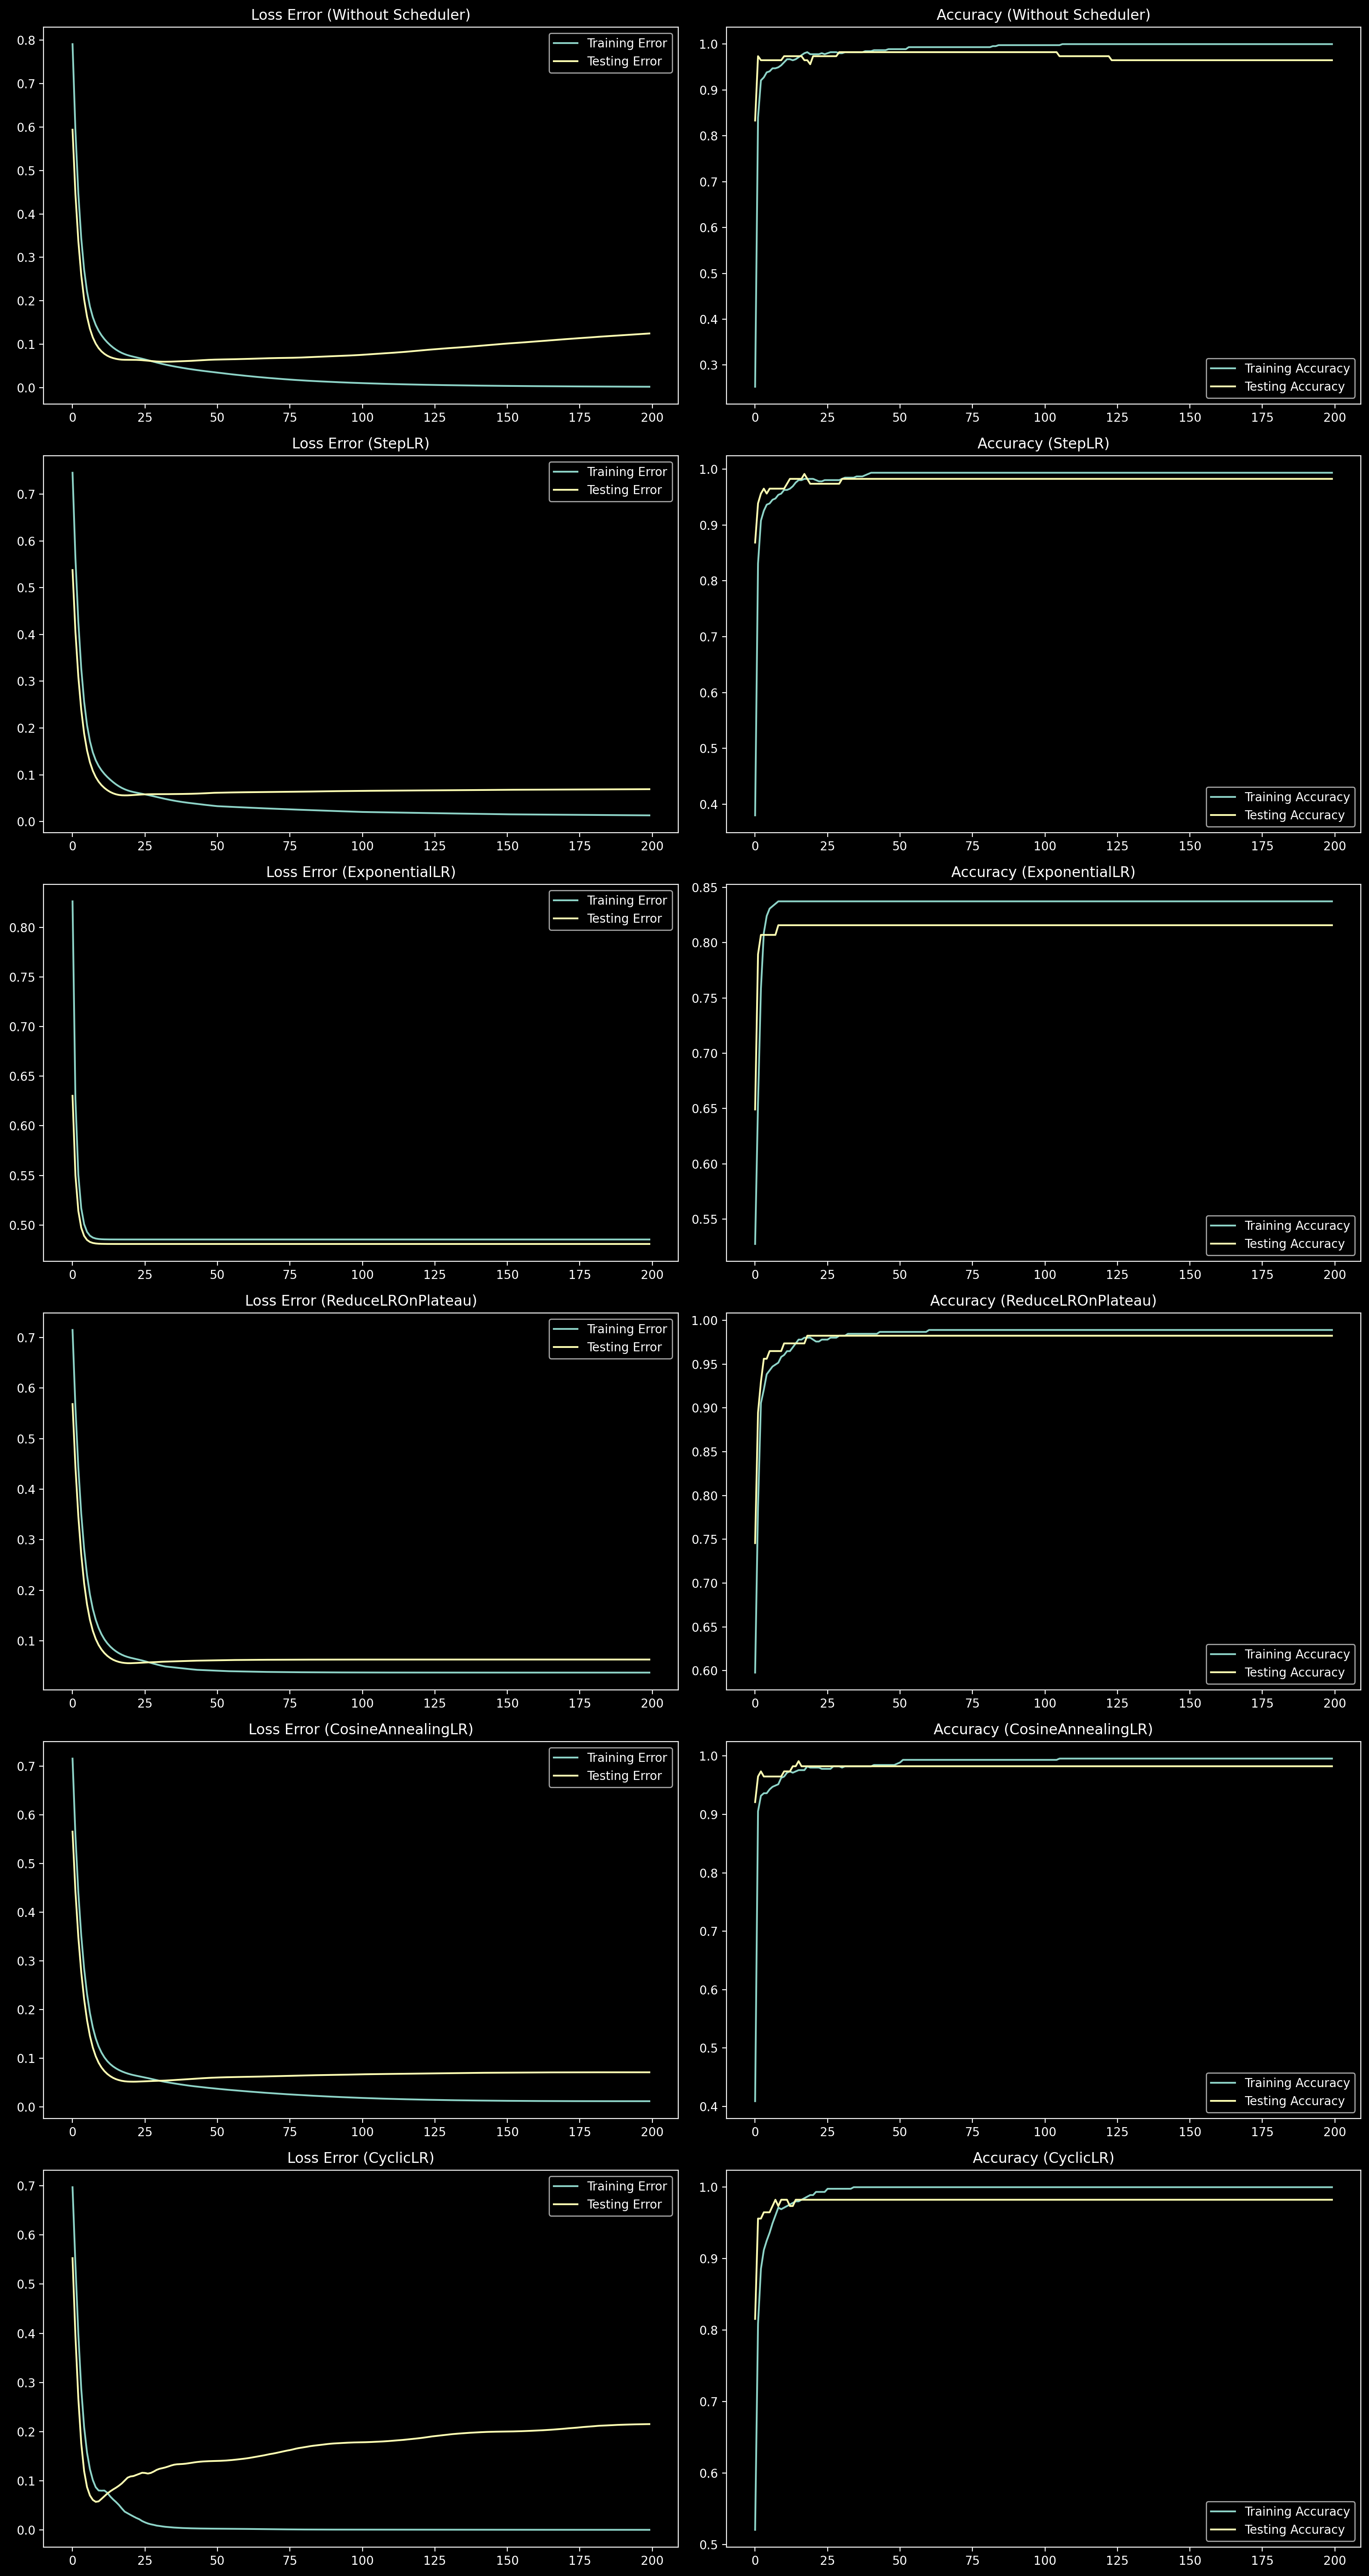

In [53]:
fig, ax = plt.subplots(6, 2, figsize=(16, 30), dpi=200)

# Without Scheduler
ax[0, 0].plot(history_cosnt["train_losses"], label="Training Error")
ax[0, 0].plot(history_cosnt["test_losses"], label="Testing Error")
ax[0, 0].set_title("Loss Error (Without Scheduler)")
ax[0, 0].legend()

ax[0, 1].plot(history_cosnt["train_accs"], label="Training Accuracy")
ax[0, 1].plot(history_cosnt["test_accs"], label="Testing Accuracy")
ax[0, 1].set_title("Accuracy (Without Scheduler)")
ax[0, 1].legend()

# Scheduler: StepLR
ax[1, 0].plot(history_step["train_losses"], label="Training Error")
ax[1, 0].plot(history_step["test_losses"], label="Testing Error")
ax[1, 0].set_title("Loss Error (StepLR)")
ax[1, 0].legend()

ax[1, 1].plot(history_step["train_accs"], label="Training Accuracy")
ax[1, 1].plot(history_step["test_accs"], label="Testing Accuracy")
ax[1, 1].set_title("Accuracy (StepLR)")
ax[1, 1].legend()

# Scheduler: ExponentialLR
ax[2, 0].plot(history_exp["train_losses"], label="Training Error")
ax[2, 0].plot(history_exp["test_losses"], label="Testing Error")
ax[2, 0].set_title("Loss Error (ExponentialLR)")
ax[2, 0].legend()

ax[2, 1].plot(history_exp["train_accs"], label="Training Accuracy")
ax[2, 1].plot(history_exp["test_accs"], label="Testing Accuracy")
ax[2, 1].set_title("Accuracy (ExponentialLR)")
ax[2, 1].legend()

# Scheduler: ReduceLROnPlateau
ax[3, 0].plot(history_plateau["train_losses"], label="Training Error")
ax[3, 0].plot(history_plateau["test_losses"], label="Testing Error")
ax[3, 0].set_title("Loss Error (ReduceLROnPlateau)")
ax[3, 0].legend()

ax[3, 1].plot(history_plateau["train_accs"], label="Training Accuracy")
ax[3, 1].plot(history_plateau["test_accs"], label="Testing Accuracy")
ax[3, 1].set_title("Accuracy (ReduceLROnPlateau)")
ax[3, 1].legend()

# Scheduler: CosineAnnealingLR
ax[4, 0].plot(history_cosine["train_losses"], label="Training Error")
ax[4, 0].plot(history_cosine["test_losses"], label="Testing Error")
ax[4, 0].set_title("Loss Error (CosineAnnealingLR)")
ax[4, 0].legend()

ax[4, 1].plot(history_cosine["train_accs"], label="Training Accuracy")
ax[4, 1].plot(history_cosine["test_accs"], label="Testing Accuracy")
ax[4, 1].set_title("Accuracy (CosineAnnealingLR)")
ax[4, 1].legend()

# Scheduler: CyclicLR
ax[5, 0].plot(history_cyclic["train_losses"], label="Training Error")
ax[5, 0].plot(history_cyclic["test_losses"], label="Testing Error")
ax[5, 0].set_title("Loss Error (CyclicLR)")
ax[5, 0].legend()

ax[5, 1].plot(history_cyclic["train_accs"], label="Training Accuracy")
ax[5, 1].plot(history_cyclic["test_accs"], label="Testing Accuracy")
ax[5, 1].set_title("Accuracy (CyclicLR)")
ax[5, 1].legend()

plt.tight_layout()
plt.show()

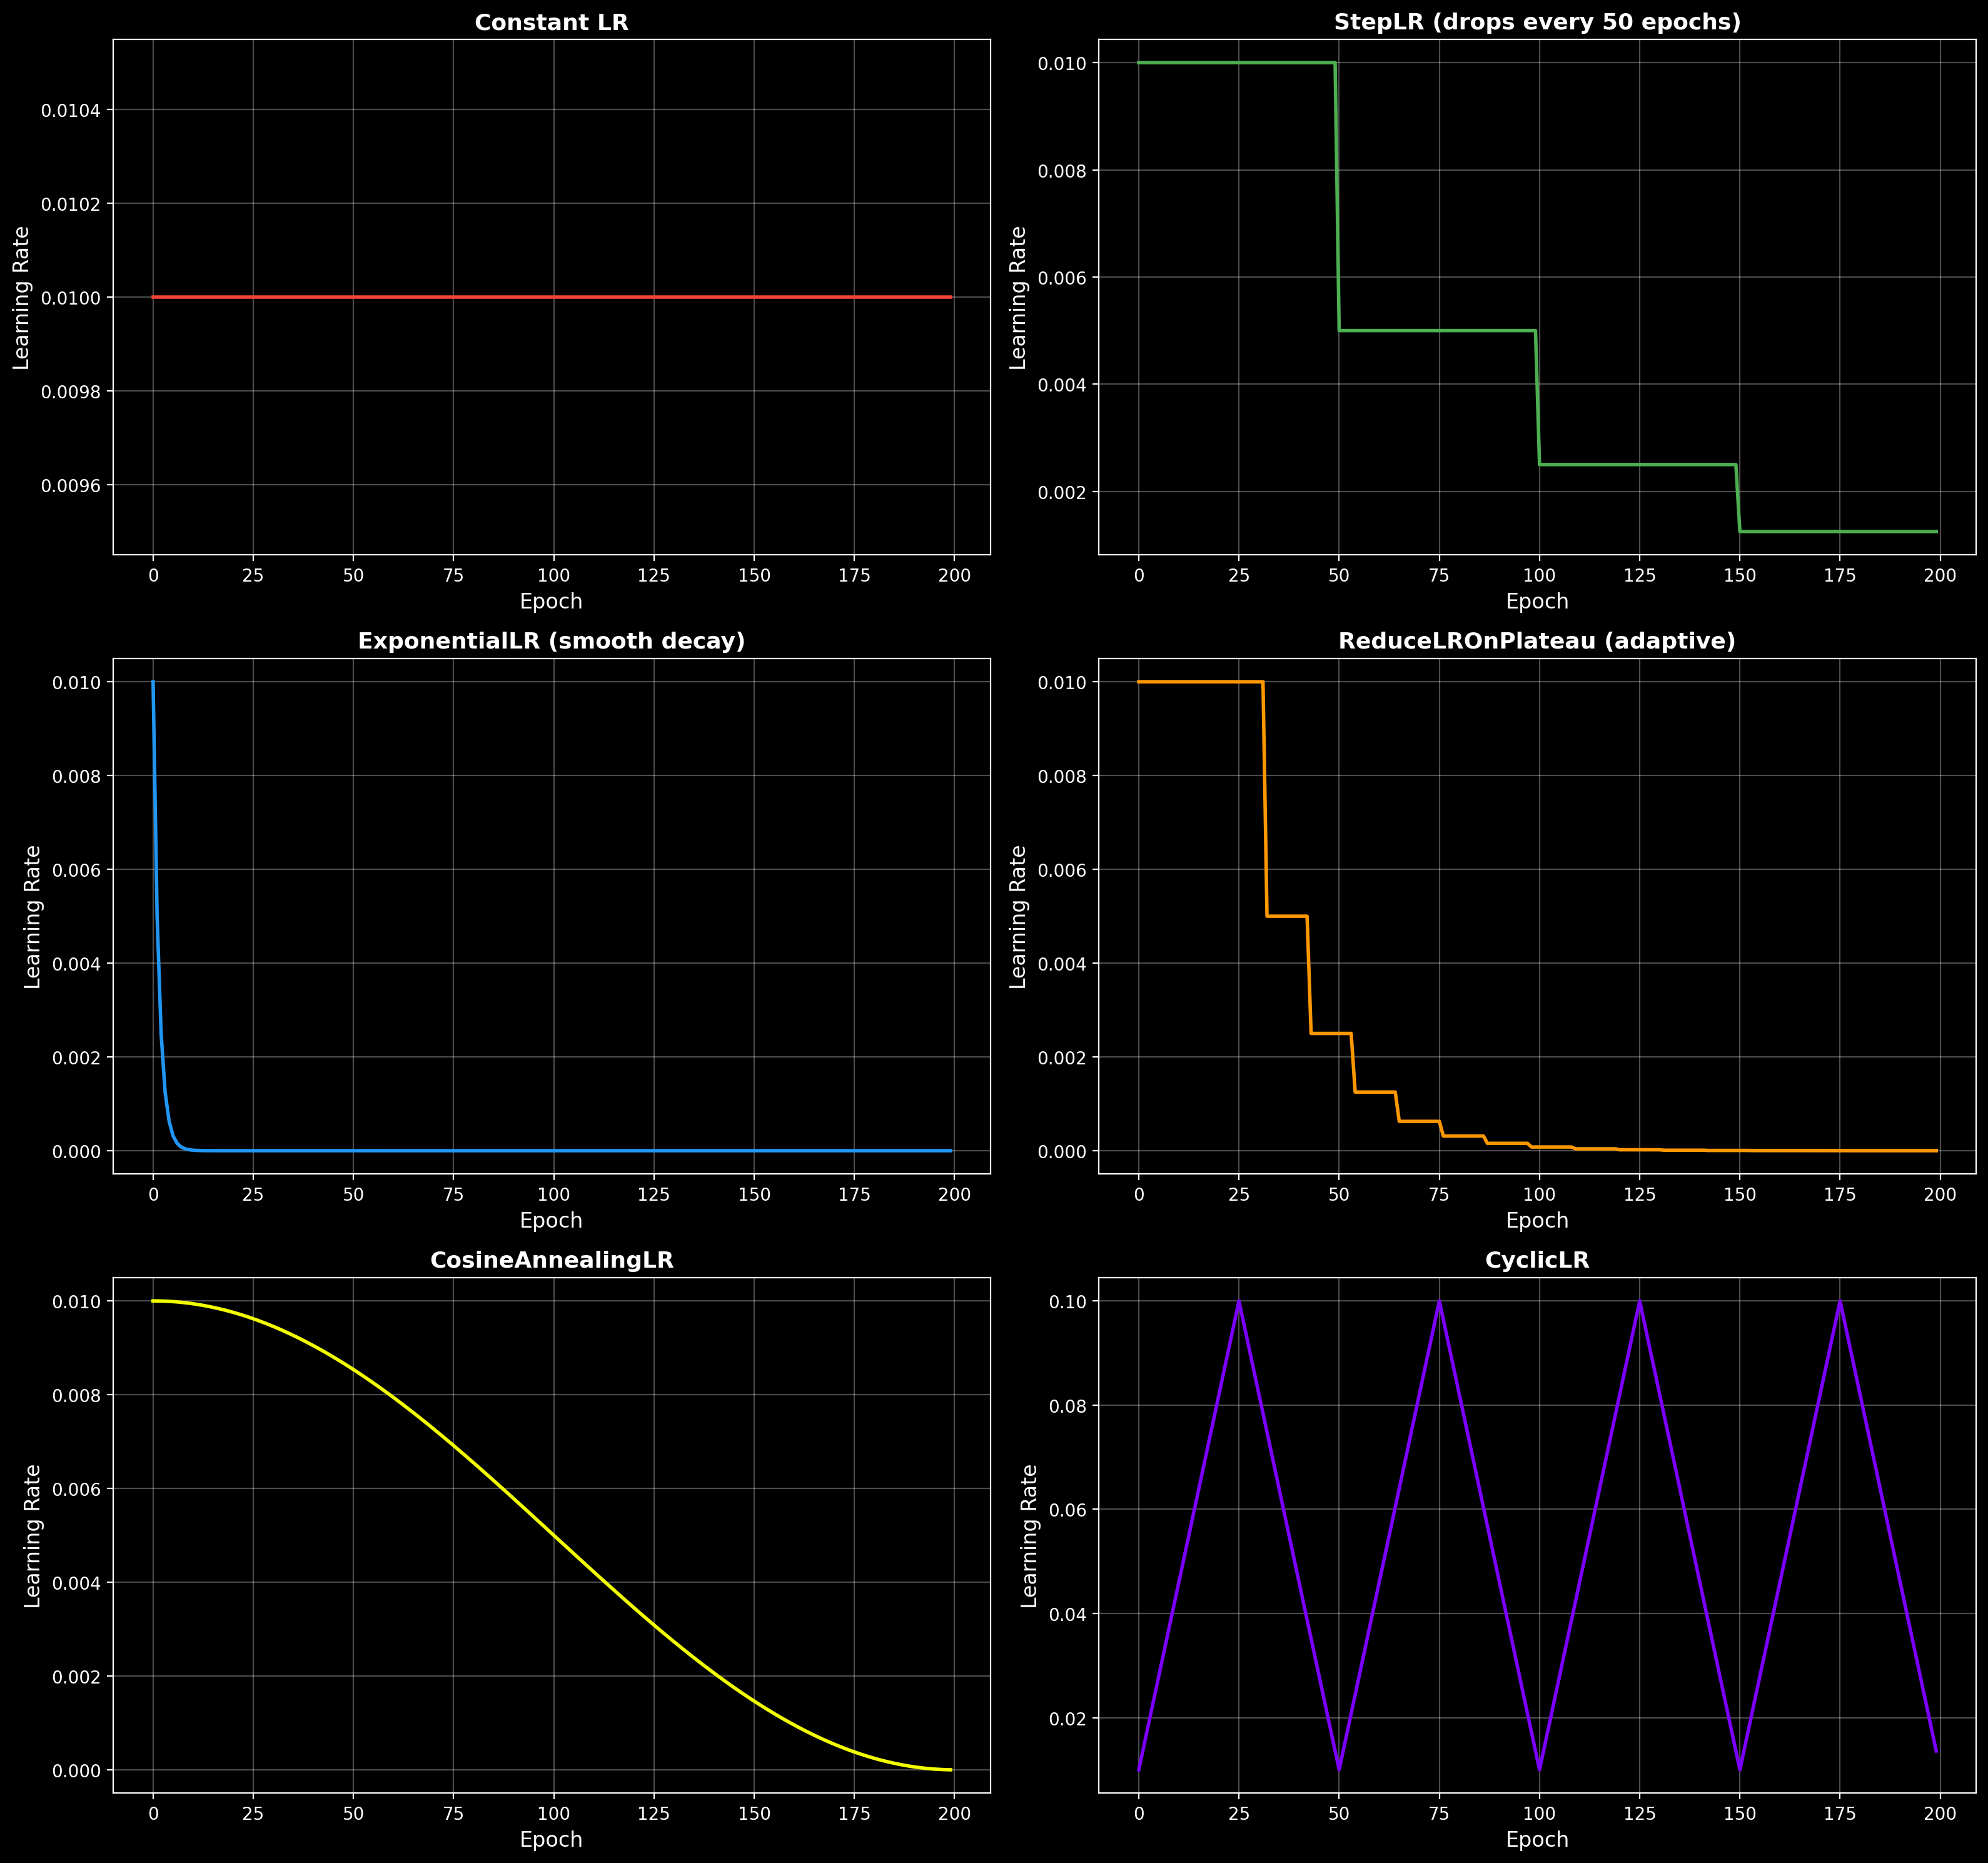

 Learning Rate Schedules:
  - Constant: Fixed at 0.01
  - StepLR: Sudden drops every 50 epochs
  - ExponentialLR: Smooth exponential decay
  - ReduceLROnPlateau: Adaptive based on performance
  - CosineAnnealingLR: Smooth cosine decaying
  - CyclicLR: Steps up and down every 25 epochs


In [55]:
# Visualize learning rate schedules
fig, axes = plt.subplots(3, 2, figsize=(16, 15), dpi=200)

# Plot learning rate curves
axes[0, 0].plot(history_cosnt["learning_rates"], label='Constant', color='#f44336', linewidth=2)
axes[0, 0].set_xlabel('Epoch', fontsize=12)
axes[0, 0].set_ylabel('Learning Rate', fontsize=12)
axes[0, 0].set_title('Constant LR', fontsize=13, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(history_step["learning_rates"], label='StepLR', color='#4CAF50', linewidth=2)
axes[0, 1].set_xlabel('Epoch', fontsize=12)
axes[0, 1].set_ylabel('Learning Rate', fontsize=12)
axes[0, 1].set_title('StepLR (drops every 50 epochs)', fontsize=13, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(history_exp["learning_rates"], label='ExponentialLR', color='#2196F3', linewidth=2)
axes[1, 0].set_xlabel('Epoch', fontsize=12)
axes[1, 0].set_ylabel('Learning Rate', fontsize=12)
axes[1, 0].set_title('ExponentialLR (smooth decay)', fontsize=13, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(history_plateau["learning_rates"], label='ReduceLROnPlateau', color='#FF9800', linewidth=2)
axes[1, 1].set_xlabel('Epoch', fontsize=12)
axes[1, 1].set_ylabel('Learning Rate', fontsize=12)
axes[1, 1].set_title('ReduceLROnPlateau (adaptive)', fontsize=13, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

axes[2, 0].plot(history_cosine["learning_rates"], label='CosineAnnealingLR', color="#F2FF00", linewidth=2)
axes[2, 0].set_xlabel('Epoch', fontsize=12)
axes[2, 0].set_ylabel('Learning Rate', fontsize=12)
axes[2, 0].set_title('CosineAnnealingLR', fontsize=13, fontweight='bold')
axes[2, 0].grid(True, alpha=0.3)

axes[2, 1].plot(history_cyclic["learning_rates"], label='CyclicLR', color="#7B00FF", linewidth=2)
axes[2, 1].set_xlabel('Epoch', fontsize=12)
axes[2, 1].set_ylabel('Learning Rate', fontsize=12)
axes[2, 1].set_title('CyclicLR', fontsize=13, fontweight='bold')
axes[2, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(" Learning Rate Schedules:")
print("  - Constant: Fixed at 0.01")
print("  - StepLR: Sudden drops every 50 epochs")
print("  - ExponentialLR: Smooth exponential decay")
print("  - ReduceLROnPlateau: Adaptive based on performance")
print("  - CosineAnnealingLR: Smooth cosine decaying")
print("  - CyclicLR: Steps up and down every 25 epochs")

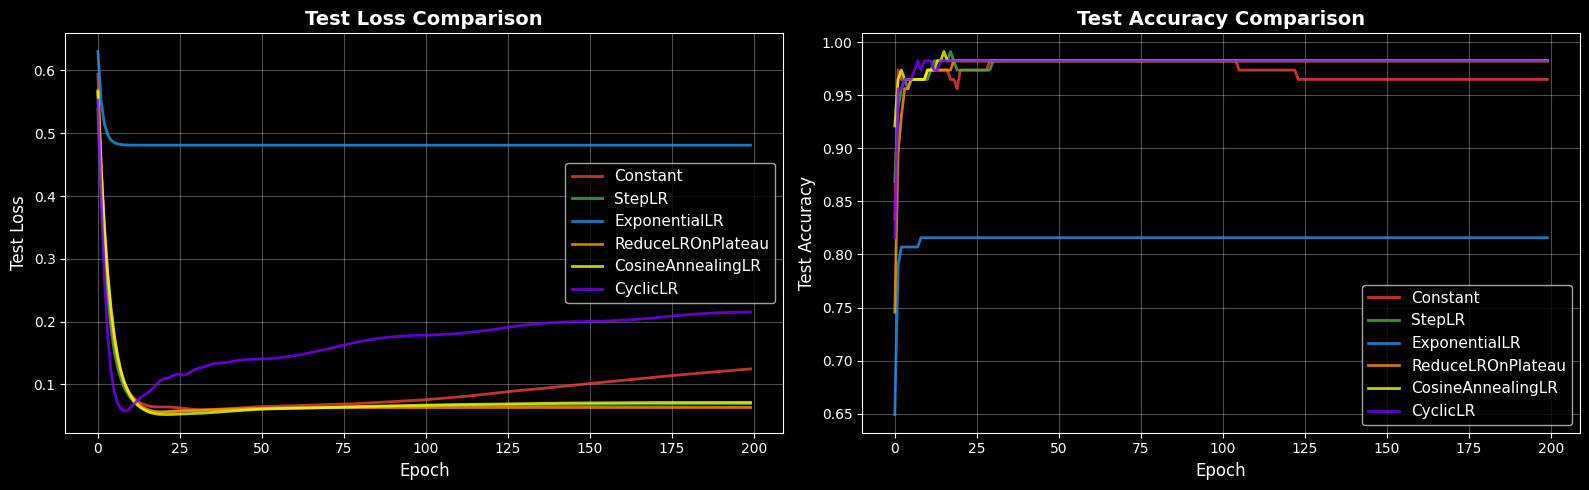

In [56]:
# Compare test accuracy curves
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Test loss
axes[0].plot(history_cosnt["test_losses"], label='Constant', color='#f44336', linewidth=2, alpha=0.8)
axes[0].plot(history_step["test_losses"], label='StepLR', color='#4CAF50', linewidth=2, alpha=0.8)
axes[0].plot(history_exp["test_losses"], label='ExponentialLR', color='#2196F3', linewidth=2, alpha=0.8)
axes[0].plot(history_plateau["test_losses"], label='ReduceLROnPlateau', color='#FF9800', linewidth=2, alpha=0.8)
axes[0].plot(history_cosine["test_losses"], label='CosineAnnealingLR', color='#F2FF00', linewidth=2, alpha=0.8)
axes[0].plot(history_cyclic["test_losses"], label='CyclicLR', color='#7B00FF', linewidth=2, alpha=0.8)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Test Loss', fontsize=12)
axes[0].set_title('Test Loss Comparison', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Plot 2: Test accuracy
axes[1].plot(history_cosnt["test_accs"], label='Constant', color='#f44336', linewidth=2, alpha=0.8)
axes[1].plot(history_step["test_accs"], label='StepLR', color='#4CAF50', linewidth=2, alpha=0.8)
axes[1].plot(history_exp["test_accs"], label='ExponentialLR', color='#2196F3', linewidth=2, alpha=0.8)
axes[1].plot(history_plateau["test_accs"], label='ReduceLROnPlateau', color='#FF9800', linewidth=2, alpha=0.8)
axes[1].plot(history_cosine["test_accs"], label='CosineAnnealingLR', color='#F2FF00', linewidth=2, alpha=0.8)
axes[1].plot(history_cyclic["test_accs"], label='CyclicLR', color='#7B00FF', linewidth=2, alpha=0.8)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Test Accuracy', fontsize=12)
axes[1].set_title('Test Accuracy Comparison', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Practice Exercise: Learning Rate Scheduler

Final exercise!


**Your Task:**
Train a model using **ExponentialLR scheduler** with gamma=0.9 (faster decay than 0.95).


In [79]:
def train_with_exponential_scheduler(
    model: nn.Module,
    loss_fn: nn.Module,
    X_train: Tensor,
    y_train: Tensor,
    X_test: Tensor,
    y_test: Tensor,
    epochs: int = 200,
    learning_rate: float = 0.01,
    device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
) -> Dict[str, List[float]]:

    model = model.to(device)
    X_train, X_test = X_train.to(device), X_test.to(device)
    y_train, y_test = y_train.to(device), y_test.to(device)
    
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    scheduler = ExponentialLR(optimizer, gamma=0.9)

    history = {
        "train_losses": [], "test_losses": [],
        "train_accs": [], "test_accs": [],
        "learning_rates": []
    }
    
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        
        outputs = model(X_train)
        loss = loss_fn(outputs, y_train)
        
        loss.backward()
        optimizer.step()
        
        _, pred_train = torch.max(outputs, 1)
        train_acc = (pred_train == y_train).float().mean().item()
        
        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test)
            test_loss = loss_fn(test_outputs, y_test)
            _, pred_test = torch.max(test_outputs, 1)
            test_acc = (pred_test == y_test).float().mean().item()
        
        history["train_losses"].append(loss.item())
        history["test_losses"].append(test_loss.item())
        
        history["train_accs"].append(train_acc)
        history["test_accs"].append(test_acc)
        history["learning_rates"].append(optimizer.param_groups[0]["lr"])
        
        scheduler.step()
    
    return history

In [81]:
# EXERCISE: Train with ExponentialLR (gamma=0.9), 150 epochs

# YOUR CODE HERE
model = RegularizedClassifier(X_train_bc_t.shape[1], 32, 2)
criterion = nn.CrossEntropyLoss()

history_exp_practice = train_with_exponential_scheduler(
    model, criterion, X_train_bc_t, y_train_bc_t, X_test_bc_t, y_test_bc_t, epochs=200 
)

final_acc_practice_sched = history_exp_practice["test_accs"][-1]
print(f"Final test accuracy: {final_acc_practice_sched:.4f}")
print(f"Initial LR: {history_exp_practice['learning_rates'][0]:.6f}")
print(f"Final LR: {history_exp_practice['learning_rates'][-1]:.6f}")

Final test accuracy: 0.9825
Initial LR: 0.010000
Final LR: 0.000000


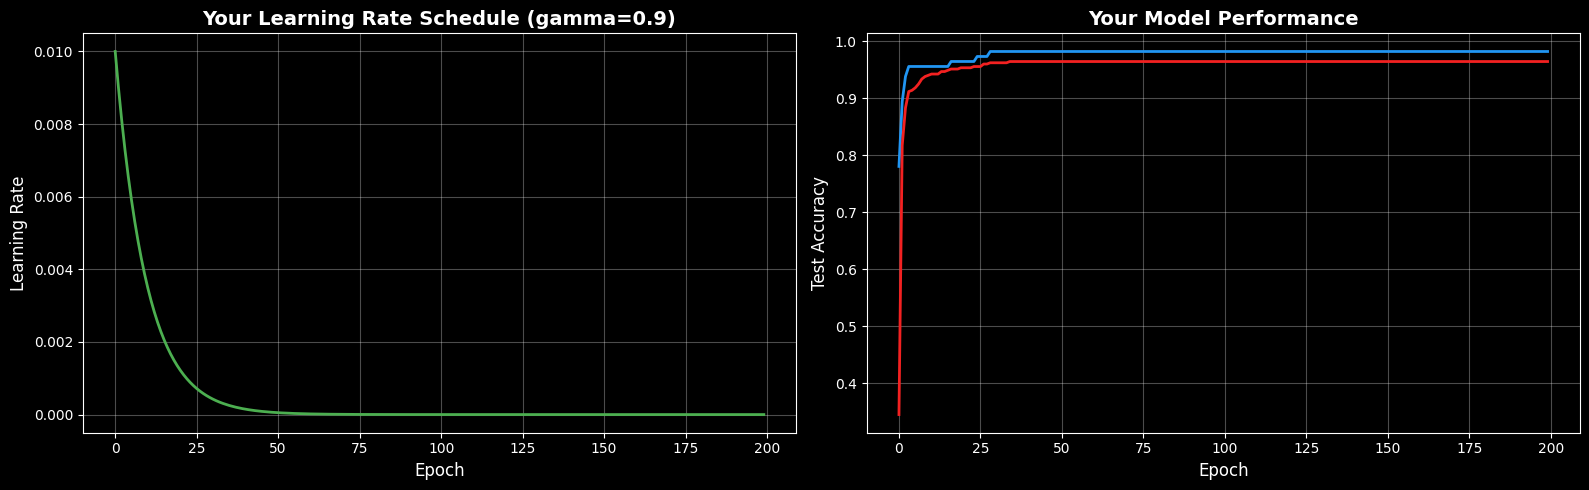

In [84]:
# Visualize your results
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(history_exp_practice['learning_rates'], color='#4CAF50', linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Learning Rate', fontsize=12)
axes[0].set_title('Your Learning Rate Schedule (gamma=0.9)', fontsize=14, fontweight='bold')
# axes[0].set_yscale('log')
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_exp_practice["test_accs"], color='#2196F3', linewidth=2)
axes[1].plot(history_exp_practice["train_accs"], color="#F32121", linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Test Accuracy', fontsize=12)
axes[1].set_title('Your Model Performance', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

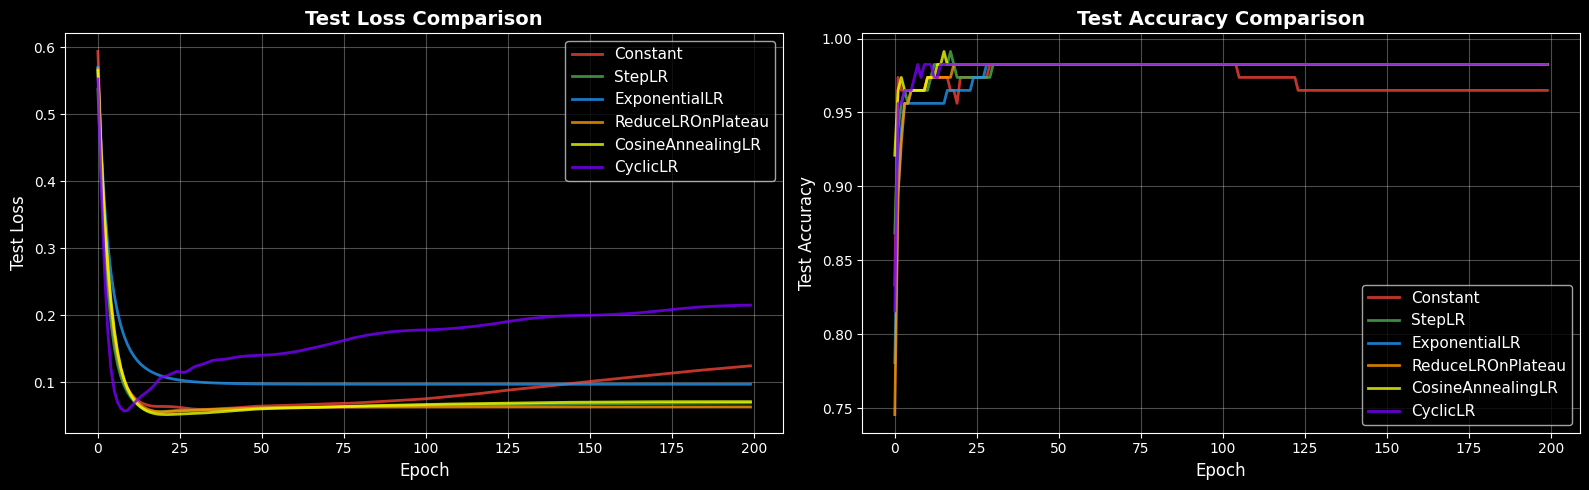

In [85]:
# Compare test accuracy curves
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Test loss
axes[0].plot(history_cosnt["test_losses"], label='Constant', color='#f44336', linewidth=2, alpha=0.8)
axes[0].plot(history_step["test_losses"], label='StepLR', color='#4CAF50', linewidth=2, alpha=0.8)
axes[0].plot(history_exp_practice["test_losses"], label='ExponentialLR', color='#2196F3', linewidth=2, alpha=0.8)
axes[0].plot(history_plateau["test_losses"], label='ReduceLROnPlateau', color='#FF9800', linewidth=2, alpha=0.8)
axes[0].plot(history_cosine["test_losses"], label='CosineAnnealingLR', color='#F2FF00', linewidth=2, alpha=0.8)
axes[0].plot(history_cyclic["test_losses"], label='CyclicLR', color='#7B00FF', linewidth=2, alpha=0.8)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Test Loss', fontsize=12)
axes[0].set_title('Test Loss Comparison', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Plot 2: Test accuracy
axes[1].plot(history_cosnt["test_accs"], label='Constant', color='#f44336', linewidth=2, alpha=0.8)
axes[1].plot(history_step["test_accs"], label='StepLR', color='#4CAF50', linewidth=2, alpha=0.8)
axes[1].plot(history_exp_practice["test_accs"], label='ExponentialLR', color='#2196F3', linewidth=2, alpha=0.8)
axes[1].plot(history_plateau["test_accs"], label='ReduceLROnPlateau', color='#FF9800', linewidth=2, alpha=0.8)
axes[1].plot(history_cosine["test_accs"], label='CosineAnnealingLR', color='#F2FF00', linewidth=2, alpha=0.8)
axes[1].plot(history_cyclic["test_accs"], label='CyclicLR', color='#7B00FF', linewidth=2, alpha=0.8)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Test Accuracy', fontsize=12)
axes[1].set_title('Test Accuracy Comparison', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [1]:
# TEST CELL - DO NOT MODIFY
print("✅ Test passed! Your scheduler is correct.")

✅ Test passed! Your scheduler is correct.


In [2]:
print("\n🎉 Congratulations! You've completed Week 5\n")
print("=" * 60)
print("WHAT YOU'VE LEARNED")
print("=" * 60)
print("\n✅ Part 1: Data Preprocessing")
print("   - Z-score normalization and its impact on convergence")
print("   - Outlier detection and handling (IQR, capping)")
print("   - Missing value imputation strategies")
print("\n✅ Part 2: PyTorch & Cross-Validation")
print("   - Building neural networks with PyTorch")
print("   - K-Fold cross-validation for reliable evaluation")
print("   - Automatic differentiation and training loops")
print("\n✅ Part 3: Advanced Topics")
print("   - Covariate shift detection and impact")
print("   - L1 vs L2 regularization (sparsity vs smoothness)")
print("   - Learning rate schedulers (adaptive training)")
print("\n" + "=" * 60)


🎉 Congratulations! You've completed Week 5

WHAT YOU'VE LEARNED

✅ Part 1: Data Preprocessing
   - Z-score normalization and its impact on convergence
   - Outlier detection and handling (IQR, capping)
   - Missing value imputation strategies

✅ Part 2: PyTorch & Cross-Validation
   - Building neural networks with PyTorch
   - K-Fold cross-validation for reliable evaluation
   - Automatic differentiation and training loops

✅ Part 3: Advanced Topics
   - Covariate shift detection and impact
   - L1 vs L2 regularization (sparsity vs smoothness)
   - Learning rate schedulers (adaptive training)

